# DTC – V08682A – final runs for the DTC chapter

Everything needed for the chapter, in order:

1. **Pre-training** (40 epochs): reconstruction, losses, table of the losses.
2. **Scans with the Euclidean metric** (30 epochs), to justify the choices of the final runs:
   - $\gamma = 10, 100, 1000, 10000$ with 2 clusters;
   - 2, 3, 4 clusters with $\gamma = 1000$.
3. **Final runs, ACF / Euclidean / CID** (2 clusters, $\gamma = 1000$, `TRAINING_EPOCHS` epochs, from the **same** pre-trained TAE and seed):
   reconstruction, losses and table, separation in energy and A/E + rise time on training, validation and test set.
4. **Comparison** of the three metrics, with A/E as reference.

All the plots go to `/storage/rasera/DeepTemporalClusteringForL200/finalplots` with no subfolders: the file names start with the
run they belong to (`pretrain_...`, `scan_eucl_gamma1000_...`, `scan_eucl_3cl_...`, `acf_...`, `eucl_...`, `cid_...`).
Every table is shown here and also saved in the same folder as `.csv` and `.tex` (LaTeX `tabular`, ready for `\input`).

**If you re-run the import cell, re-run also the PARAMETERS cell**: importing `preliminary` / `DeepTemporalClustering` reloads `pf`
and resets `PLOT_DIR`, `TAG` and `PREFIX`.

In [5]:
import sys, os
sys.path.append(os.path.abspath('..'))     # common modules live in the main folder

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import importlib

import preliminary
importlib.reload(preliminary)
import plottingfunctions as pf
importlib.reload(pf)
import DeepTemporalClustering as DTC
importlib.reload(DTC)
import loadercreator
importlib.reload(loadercreator)

assert hasattr(pf, 'PREFIX'), "use the plottingfunctions.py with PREFIX (all the plots in one folder)"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("The device I'm using is:", device)
print("wfcleaningNEW in use:", preliminary.wfcleaning.__file__)

The device I'm using is: cuda
wfcleaningNEW in use: /storage/rasera/DeepTemporalClusteringForL200/wfcleaningNEW.py


# SANITY CHECKS

In [6]:
preliminary.sanity_check(use_charge=False)
preliminary.sanity_check(use_charge=True)
preliminary.sanity_check_dtc(use_charge=False)
preliminary.sanity_check_dtc(use_charge=True)

use_charge=False
  input shape:         (4, 1, 200)
  latent shape:        (4, 1, 20)  (atteso: (4, 1, 20))
  reconstructed shape: (4, 1, 200)  (atteso: (4, 1, 200))
  loss: 229511168.0000
  parametri senza gradiente: 0 (atteso: 0)
  logvar_obs.grad: [-2.2951253e+08]
  OK

use_charge=True
  input shape:         (4, 2, 200)
  latent shape:        (4, 1, 20)  (atteso: (4, 1, 20))
  reconstructed shape: (4, 2, 200)  (atteso: (4, 2, 200))
  loss: 205035344.0000
  parametri senza gradiente: 0 (atteso: 0)
  logvar_obs.grad: [-2.0348741e+08 -1.5501519e+06]
  OK

use_charge=False
  input shape:         (4, 1, 200)
  reconstructed shape: (4, 1, 200)  (atteso: (4, 1, 200))
  q shape:             (4, 2)  (atteso: (4, 2))
  q.sum(dim=1):        [1. 1. 1. 1.]  (atteso: tutti ~1.0)
  numero di tensori allenabili: 24  (atteso: > 0)
  loss: 197570304.0000
  parametri senza gradiente: 0 (atteso: 0)
  clusters.grad è None: False (atteso: False)
  OK

use_charge=True
  input shape:         (4, 2, 200)
  

# PARAMETERS

In [7]:
# ---------------- data / loaders ----------------
use_charge = False       # True: current + charge (2 channels) | False: current only
normalised = False       # True: corrente normalizzata a 1 evento per evento | False: corrente con ampiezza (A/E)
use_sigma  = False       # True: solo gli eventi nelle finestre SSE (DEP) e MSE (FEP) | False: tutta la finestra 1550-1650 keV
scale      = True        # True: corrente divisa per la mediana dei massimi del training set | False: nessuna scala

# ---------------- pre-training ----------------
PRETRAINING_EPOCHS = 50

# ---------------- choices of the final runs ----------------
N_CLUSTERS      = 2
GAMMA           = 1000
TRAINING_EPOCHS = 20           # final runs of the three metrics (still to be decided)
SEED            = 0            # same seed for every run: same KMeans start, same batch order

# ---------------- scans (Euclidean metric) ----------------
SCAN_METRIC   = 'eucl'
SCAN_EPOCHS   = 20
SCAN_GAMMAS   = [10, 100, 1000, 10000]      # with N_CLUSTERS clusters
SCAN_CLUSTERS = [2, 3, 4]                   # with GAMMA

# pf.TAG -> name of the metric in DTC (pf.TAG gives the color of the metric in the plots)
METRICS = {'acf': 'acf', 'eucl': 'euclidean', 'cid': 'cid'}
NAMES   = {'acf': 'ACF', 'eucl': 'Euclidean', 'cid': 'CID'}

# ---------------- output ----------------
pf.PLOT_DIR = "/storage/rasera/DeepTemporalClusteringForL200/finalplots"   # plots AND tables, no subfolders
pf.TAG, pf.PREFIX = '', ''
TABLE_DIR = pf.PLOT_DIR
OUT_DIR   = "finalmodels"                                                  # weights and bundles of the final runs
os.makedirs(pf.PLOT_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# PRELIMINARY
Data loading, cleaning and loaders creation.

Periods to process: ['p03', 'p04', 'p05', 'p06', 'p07', 'p08', 'p09']
Period p03: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p04: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p05: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p06: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p07: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p08: checkpoint loaded from /storage/rasera/clean_data_V08682A
Period p09: checkpoint loaded from /storage/rasera/clean_data_V08682A
Totale su 7 periodi: 349002 eventi (116985 dopo il taglio A/E)
Waveforms shape (all periods): (349002, 1400)
Energy shape (all periods): (349002,)
Amplitude vs Energy shape (all periods): (349002,)
Rise time shape (all periods): (349002,)
Waveforms shape after AoE cut (all periods): (116985, 1400)
Energy shape after AoE cut (all periods): (116985,)
Rise time shape after AoE cut (all periods): (116985,)
wfcleaningNEW in use: /storage/ras

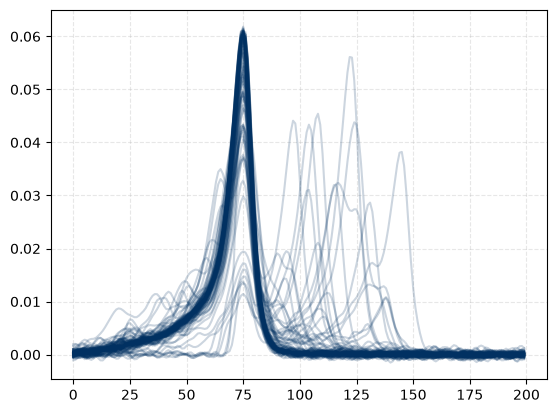

Charge aligned: (348999, 200)
Current aligned: (348999, 200)
Kept: 348999 | noise: 3 | edge: 0 | total: 349002
rise time (all events): 348999 events | NaN/inf: 0 | <= 0: 0
  mean rise time [ns]: 619.1 | median [ns]: 544.0
Charge AoE aligned: (116984, 200)
Current AoE aligned: (116984, 200)
Kept: 116984 | noise: 1 | edge: 0 | total: 116985
rise time (after A/E cut): 116984 events | NaN/inf: 0 | <= 0: 0
  mean rise time [ns]: 517.7 | median [ns]: 528.0
corrente: mediana su 50 punti 0.000456 | mediana su 10 punti 0.000314
carica: mediana su 50 punti 0.004501 | mediana su 10 punti 0.001448
use_charge: False | use_sigma: False | normalised: False | scale: True (scale factor = 0.05650758299488506) | scale_charge: False (charge scale factor = 1.0)
waves: (348999, 1, 200) | NaN/inf: 0
rumore corrente su questa scala (current_noise): 0.008069798057257726
rumore carica su questa scala (charge_noise):   0.004500837161356608
correlazione altezza picco - A/E: 0.9908282813347021
train: 279199 | val:

In [8]:
raw   = preliminary.load_data(chosen_detector="V08682A", e_min=1550, e_max=1650, output_dir="/storage/rasera/clean_data_V08682A")
clean = preliminary.clean_data(raw)
train_loader, validation_loader, all_loader, data = preliminary.create_loaders(clean, use_charge=use_charge, normalised=normalised, use_sigma=use_sigma, scale=scale)

### DEP and FEP windows
Gaussian fits on the clustered events, windows at $\pm 3\sigma$: used to find the SSE-like cluster of every run and in the tables.

In [9]:
energy = data['energy']     # same events, same order, as the cluster assignments (all_loader)

dep, _ = loadercreator.gaussian(energy, xmin=1587, xmax=1598)
fep, _ = loadercreator.gaussian(energy, xmin=1615, xmax=1626)
in_dep = np.abs(energy - dep[1]) <= 3 * dep[2]
in_fep = np.abs(energy - fep[1]) <= 3 * fep[2]

print(f"DEP: mu = {dep[1]:.2f} keV, sigma = {dep[2]:.2f} keV -> {in_dep.sum()} events in the window")
print(f"FEP: mu = {fep[1]:.2f} keV, sigma = {fep[2]:.2f} keV -> {in_fep.sum()} events in the window")

DEP: mu = 1592.40 keV, sigma = 2.10 keV -> 59254 events in the window
FEP: mu = 1620.34 keV, sigma = 2.33 keV -> 95364 events in the window


### Tables
Every table is shown and saved in `TABLE_DIR` as `.csv` and as a LaTeX `tabular` (`.tex`).

In [10]:
def _latex_escape(text):
    for a, b in (('\\', r'\textbackslash{}'), ('%', r'\%'), ('_', r'\_'), ('&', r'\&'), ('#', r'\#')):
        text = text.replace(a, b)
    return text


def save_table(df, name, decimals=2):
    """Show the table and save it as TABLE_DIR/name.csv and TABLE_DIR/name.tex."""
    display(df.round(decimals))
    df.to_csv(os.path.join(TABLE_DIR, name + '.csv'))
    fmt = lambda v: f"{v:.{decimals}f}" if isinstance(v, (float, np.floating)) else _latex_escape(str(v))
    header = [_latex_escape(str(df.index.name or ''))] + [_latex_escape(str(c)) for c in df.columns]
    lines = [r'\begin{tabular}{l' + 'r' * len(df.columns) + '}', r'\hline', ' & '.join(header) + r' \\', r'\hline']
    for idx, row in df.iterrows():
        lines.append(' & '.join([fmt(idx)] + [fmt(v) for v in row]) + r' \\')
    lines += [r'\hline', r'\end{tabular}']
    with open(os.path.join(TABLE_DIR, name + '.tex'), 'w') as fh:
        fh.write('\n'.join(lines) + '\n')
    print("saved:", os.path.join(TABLE_DIR, name + '.csv'), "|", name + '.tex')

# 1. PRE-TRAINING
Once, shared by every run of this notebook. Plots: `pretrain_reconstruction.pdf`, `pretrain_losses.pdf`.

initial sigma of the NLL: 0.00807


Pretraining on the device: cuda
[pretrain] epoch 1/50 - train: 863.8279  val: -544.5671
[pretrain] epoch 2/50 - train: -619.4686  val: -677.6899
[pretrain] epoch 3/50 - train: -708.5174  val: -732.2622
[pretrain] epoch 4/50 - train: -745.8330  val: -756.0705
[pretrain] epoch 5/50 - train: -758.9121  val: -761.1574
[pretrain] epoch 6/50 - train: -765.3958  val: -769.1698
[pretrain] epoch 7/50 - train: -770.0298  val: -772.2709
[pretrain] epoch 8/50 - train: -773.7520  val: -776.0611
[pretrain] epoch 9/50 - train: -776.6864  val: -778.2532
[pretrain] epoch 10/50 - train: -779.4476  val: -782.3049
[pretrain] epoch 11/50 - train: -781.5710  val: -784.6486
[pretrain] epoch 12/50 - train: -783.6401  val: -784.2421
[pretrain] epoch 13/50 - train: -785.3577  val: -787.6142
[pretrain] epoch 14/50 - train: -786.9178  val: -788.8592
[pretrain] epoch 15/50 - train: -788.2638  val: -788.9957
[pretrain] epoch 16/50 - train: -789.7291  val: -792.0833
[pretrain] epoch 17/50 - train: -790.9931  val: -7

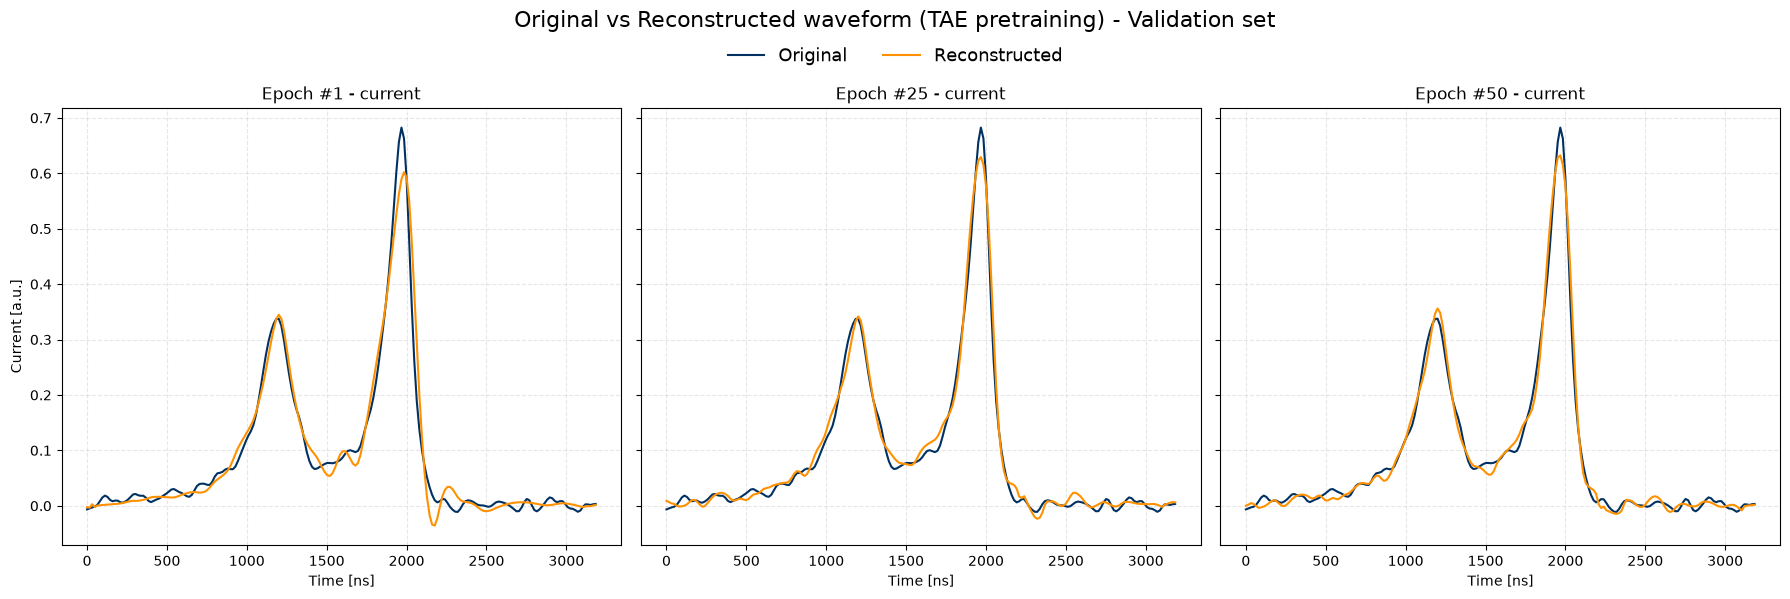

saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/tae_pretrained_50ep.pth


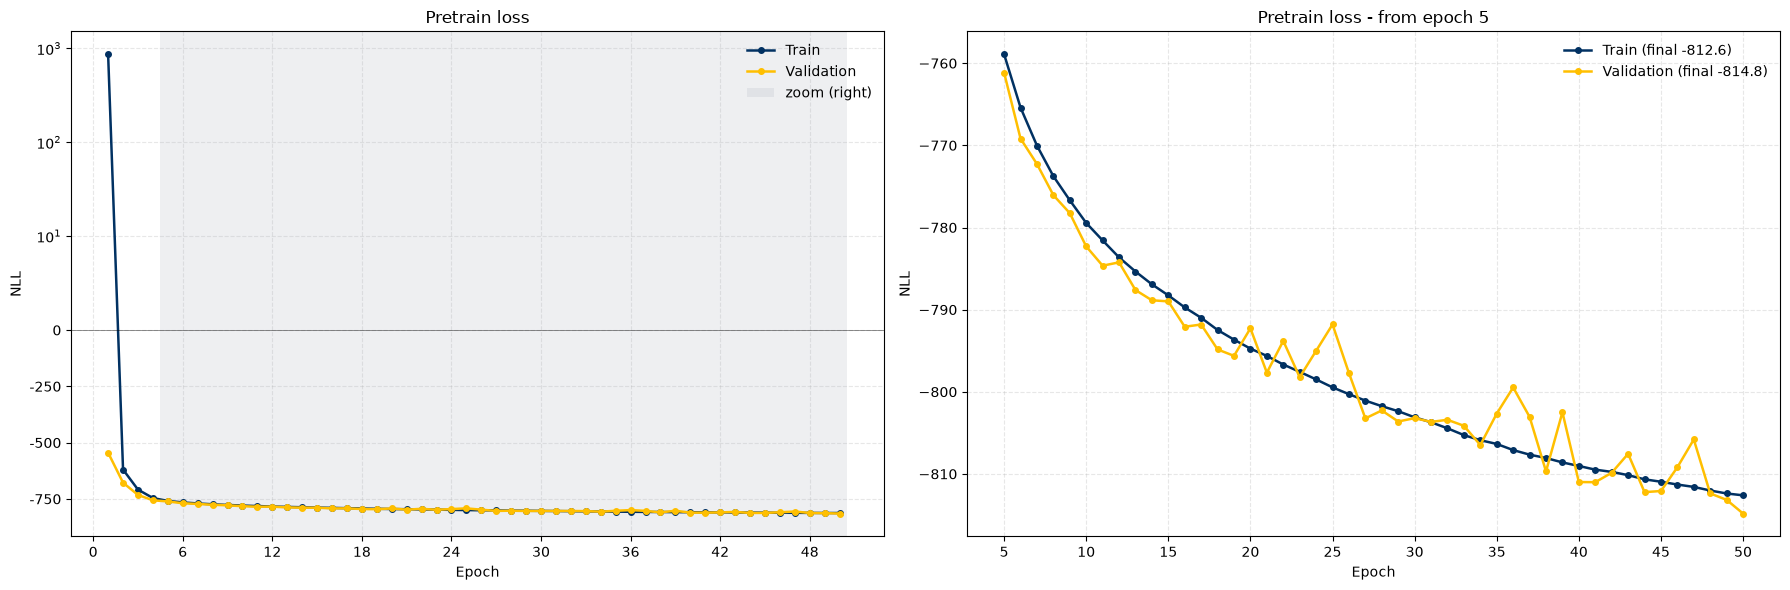

In [11]:
TAE_PATH = os.path.join(OUT_DIR, f"tae_pretrained_{PRETRAINING_EPOCHS}ep.pth")

torch.manual_seed(42)
dtc = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=N_CLUSTERS, use_charge=use_charge)

# noise of the NLL initialised from the data (baseline of the training waveforms, on the scale fed to the network)
noise = np.median(np.std(data['waves'][data['idx_train'], 0, :20], axis=1))
with torch.no_grad():
    dtc.tae.logvar_obs.fill_(float(np.log(noise ** 2)))
print(f"initial sigma of the NLL: {noise:.5f}")

pf.TAG, pf.PREFIX = '', ''
pre_train_l, pre_val_l = DTC.pretrain(dtc.tae, train_loader, validation_loader, epochs=PRETRAINING_EPOCHS)

torch.save(dtc.tae.state_dict(), TAE_PATH)
print("saved:", os.path.abspath(TAE_PATH))

pf.plot_pretrain_losses(pre_train_l, pre_val_l)

#### Table: pre-training losses

In [12]:
pre_table = pd.DataFrame({'NLL train': pre_train_l, 'NLL validation': pre_val_l},
                         index=pd.Index(np.arange(1, len(pre_train_l) + 1), name='epoch'))
save_table(pre_table, 'table_pretrain_losses')

,NLL train,NLL validation
epoch,,
1,863.83,-544.57
2,-619.47,-677.69
3,-708.52,-732.26
4,-745.83,-756.07
5,-758.91,-761.16
6,-765.40,-769.17
7,-770.03,-772.27
8,-773.75,-776.06
9,-776.69,-778.25


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_pretrain_losses.csv | table_pretrain_losses.tex


# 2. DTC TRAINING – common functions
Every run reloads the **same** pre-trained TAE, freezes `logvar_obs`, initialises the clusters with KMeans and rewinds the shuffle
with the **same** seed: two runs differ only in what is changed on purpose (metric, $\gamma$, number of clusters).

In [13]:
def cluster_run(n_clusters, distance_metric, gamma, epochs, weights=TAE_PATH, seed=SEED):
    
    torch.manual_seed(seed)
    
    assert train_loader.generator is not None, \
        "train_loader va ricostruito con epoch_loader(..., seed=...) perché questo funzioni"
    train_loader.generator.manual_seed(seed)   # riavvolge lo shuffle: indipendente da quante corse ci sono state prima
    
    model = DTC.DTC(input_length=data['waves'].shape[-1], pool_size=10, n_clusters=n_clusters,
                    distance_metric=distance_metric, use_charge=use_charge)
    model.tae.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
    model.tae.logvar_obs.requires_grad_(False)
    
    DTC.initialization_of_clusters_weights(model, train_loader, seed=seed)
    dev = next(model.parameters()).device
    y_init = DTC.cluster_assignments(model, all_loader, dev)
    
    model, tr, va, frac, chg = DTC.training(model, train_loader, validation_loader, epochs=epochs, gamma=gamma)
    y_after = DTC.cluster_assignments(model, all_loader, dev)
    
    print(f"[{distance_metric}, gamma={gamma}, {n_clusters} clusters] events that changed cluster with the training: "
          f"{(y_init != y_after).mean():.4f}")
    return dict(model=model, y_init=np.asarray(y_init), y=np.asarray(y_after), total_train=tr, total_val=va,
                gamma=gamma, n_clusters=n_clusters, metric=distance_metric)


def training_table(run):
    """Losses of every epoch of a DTC run."""
    h = run['model'].history
    frac = ['/'.join(f"{x:.2f}" for x in np.ravel(f)) for f in h['fractions']]
    return pd.DataFrame({'total train': run['total_train'], 'total validation': run['total_val'],
                         'NLL train': h['nll_train'], 'NLL validation': h['nll_val'],
                         'KL train': h['kl_train'], 'KL validation': h['kl_val'],
                         'changes [%]': 100 * np.asarray(h['changes']),
                         'events per cluster': frac},
                        index=pd.Index(np.arange(1, len(run['total_train']) + 1), name='epoch'))


def composition(y, n_clusters, mask=None):
    """Fraction of the events of every cluster, and fraction of the DEP / FEP events in every cluster."""
    m = np.ones(len(y), bool) if mask is None else np.zeros(len(y), bool)
    if mask is not None:
        m[mask] = True
    size = [float((y[m] == k).mean()) for k in range(n_clusters)]
    dep_f = [float((y[m & in_dep] == k).mean()) for k in range(n_clusters)]
    fep_f = [float((y[m & in_fep] == k).mean()) for k in range(n_clusters)]
    return size, dep_f, fep_f


def sse_like(y, n_clusters):
    """SSE-like cluster: the one with the largest (DEP fraction - FEP fraction), on all the events."""
    _, dep_f, fep_f = composition(y, n_clusters)
    return int(np.argmax(np.array(dep_f) - np.array(fep_f)))


def plot_energy_and_history(run, prefix, label):
    """Training history + clusters vs energy on the whole calibration dataset (used by the scans)."""
    pf.PREFIX = prefix
    k = run['n_clusters']
    pf.plot_training_history(run['model'].history, name=f"{k}cl_training_history")
    pf.plot_clusters_vs_energy(run['y'], energy, k, title=f"{pf._title(k, 'all', len(energy))} - {label}",
                               name=f"{k}cl_energy_all", colors=pf.cluster_colors(run['y'], energy, k))

# 2a. SCAN OF $\gamma$ (Euclidean, 30 epochs, 2 clusters)
For every $\gamma$: reconstruction after the training, training history, clusters vs energy on the whole calibration dataset
(files `scan_eucl_gamma<γ>_...`). Then one summary table.

$\gamma$ is chosen with **unsupervised** criteria (reconstruction not degraded, assignments that move away from KMeans and then
stabilise); the DEP/FEP columns are shown as a check, not used for the choice.

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.886 0.114]
[train] epoch 1/20 - train: -811.5409  val: -813.6799  events per cluster: [0.933 0.067]  changes: 0.0462
        NLL: -811.66   KL: 0.0121
[train] epoch 2/20 - train: -813.2142  val: -812.1759  events per cluster: [0.931 0.069]  changes: 0.0016
        NLL: -813.34   KL: 0.0127
[train] epoch 3/20 - train: -813.4724  val: -811.3117  events per cluster: [0.93 0.07]  changes: 0.0005
        NLL: -813.60   KL: 0.0127
[train] epoch 4/20 - train: -813.7176  val: -807.3403  events per cluster: [0.932 0.068]  changes: 0.0011
        NLL: -813.84   KL: 0.0127
[train] epoch 5/20 - train: -814.0784  val: -814.4294  events per cluster: [0.93 0.07]  changes: 0.0018
        NLL: -814.21   KL: 0.0127
[train] epoch 6/20 - train: -814.3739  val: -813.8763  events per cluster: [0.933 0.067]  changes: 0.0028
        N

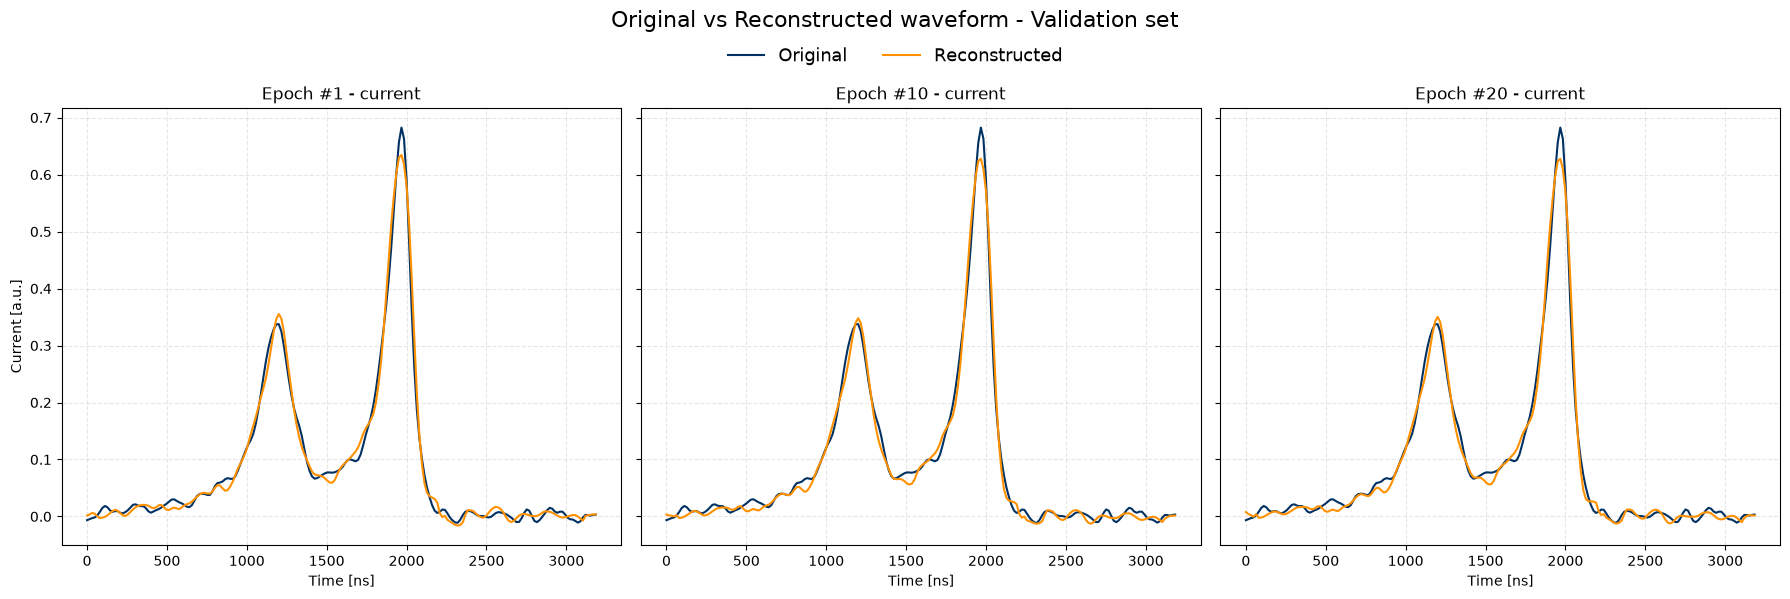

[euclidean, gamma=10, 2 clusters] events that changed cluster with the training: 0.0422


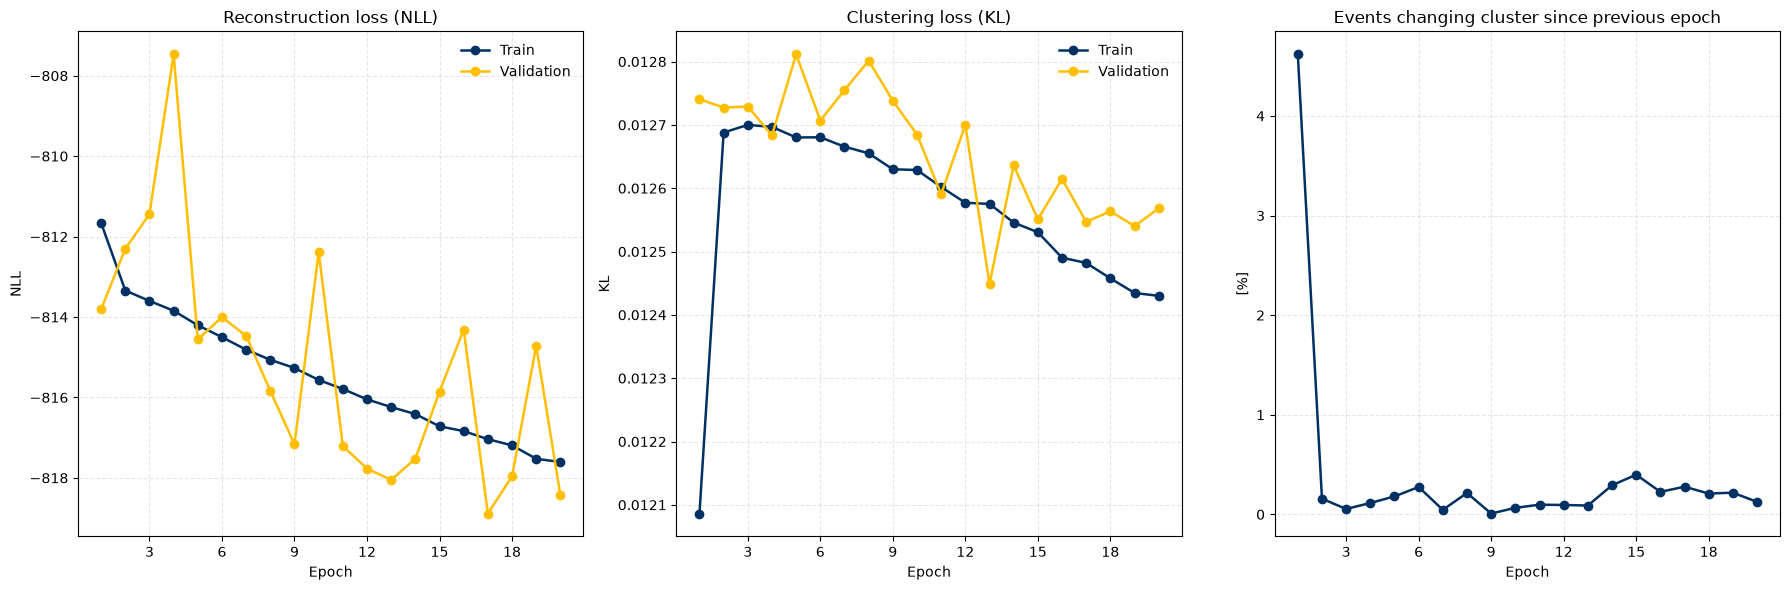

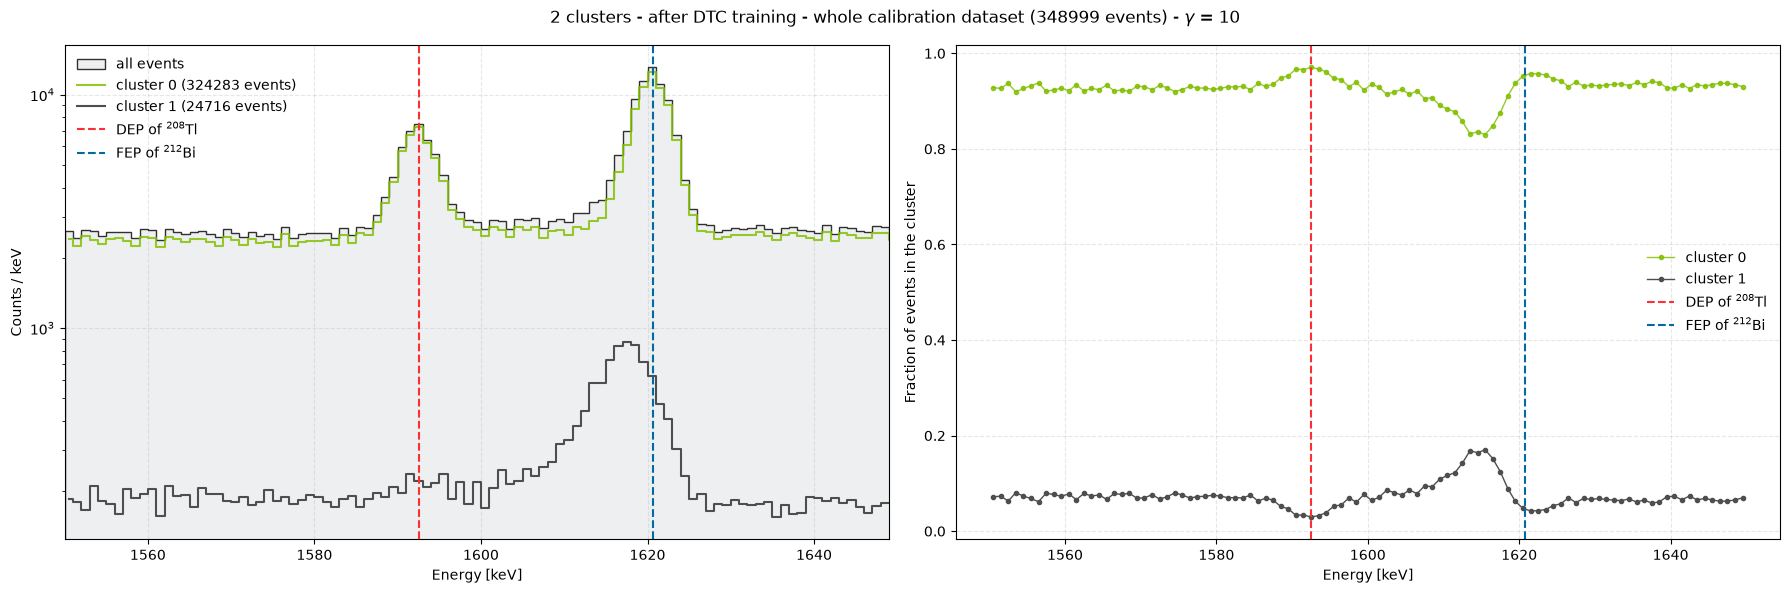

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.886 0.114]
[train] epoch 1/20 - train: -810.3952  val: -812.7224  events per cluster: [0.932 0.068]  changes: 0.0454
        NLL: -811.64   KL: 0.0124
[train] epoch 2/20 - train: -811.9521  val: -811.4832  events per cluster: [0.93 0.07]  changes: 0.0018
        NLL: -813.28   KL: 0.0133
[train] epoch 3/20 - train: -812.1984  val: -811.3606  events per cluster: [0.929 0.071]  changes: 0.0010
        NLL: -813.55   KL: 0.0136
[train] epoch 4/20 - train: -812.3798  val: -807.2478  events per cluster: [0.93 0.07]  changes: 0.0010
        NLL: -813.75   KL: 0.0137
[train] epoch 5/20 - train: -812.7616  val: -812.4879  events per cluster: [0.928 0.072]  changes: 0.0020
        NLL: -814.15   KL: 0.0139
[train] epoch 6/20 - train: -813.0095  val: -811.6187  events per cluster: [0.93 0.07]  changes: 0.0024
        NLL

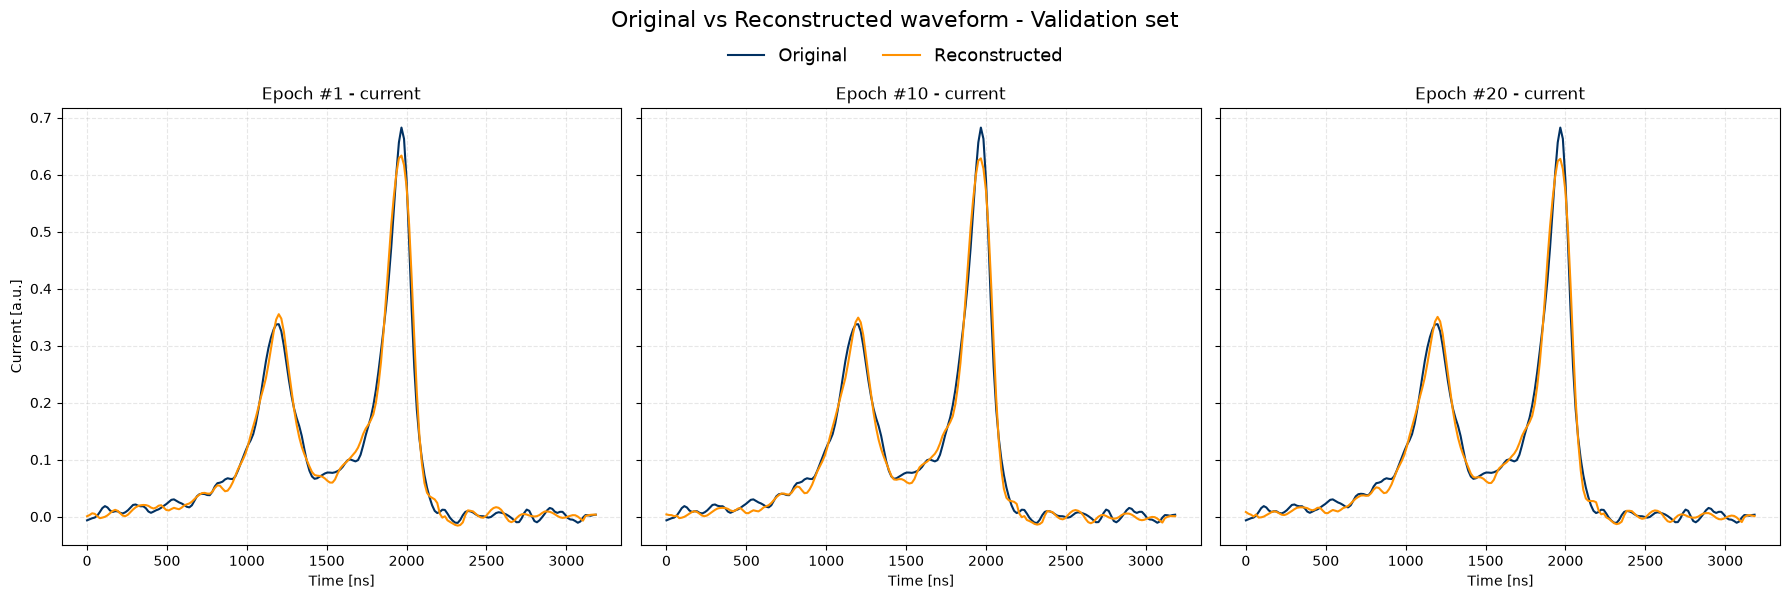

[euclidean, gamma=100, 2 clusters] events that changed cluster with the training: 0.0371


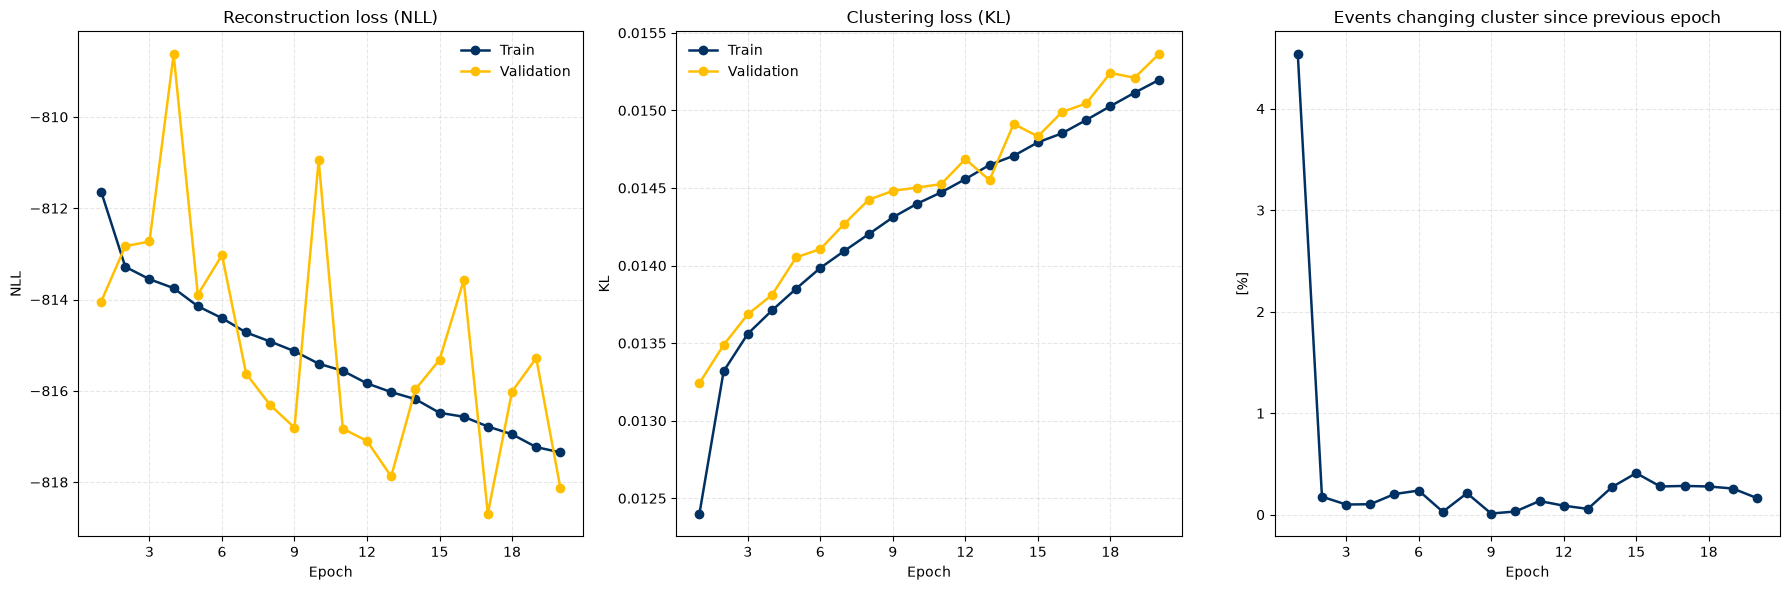

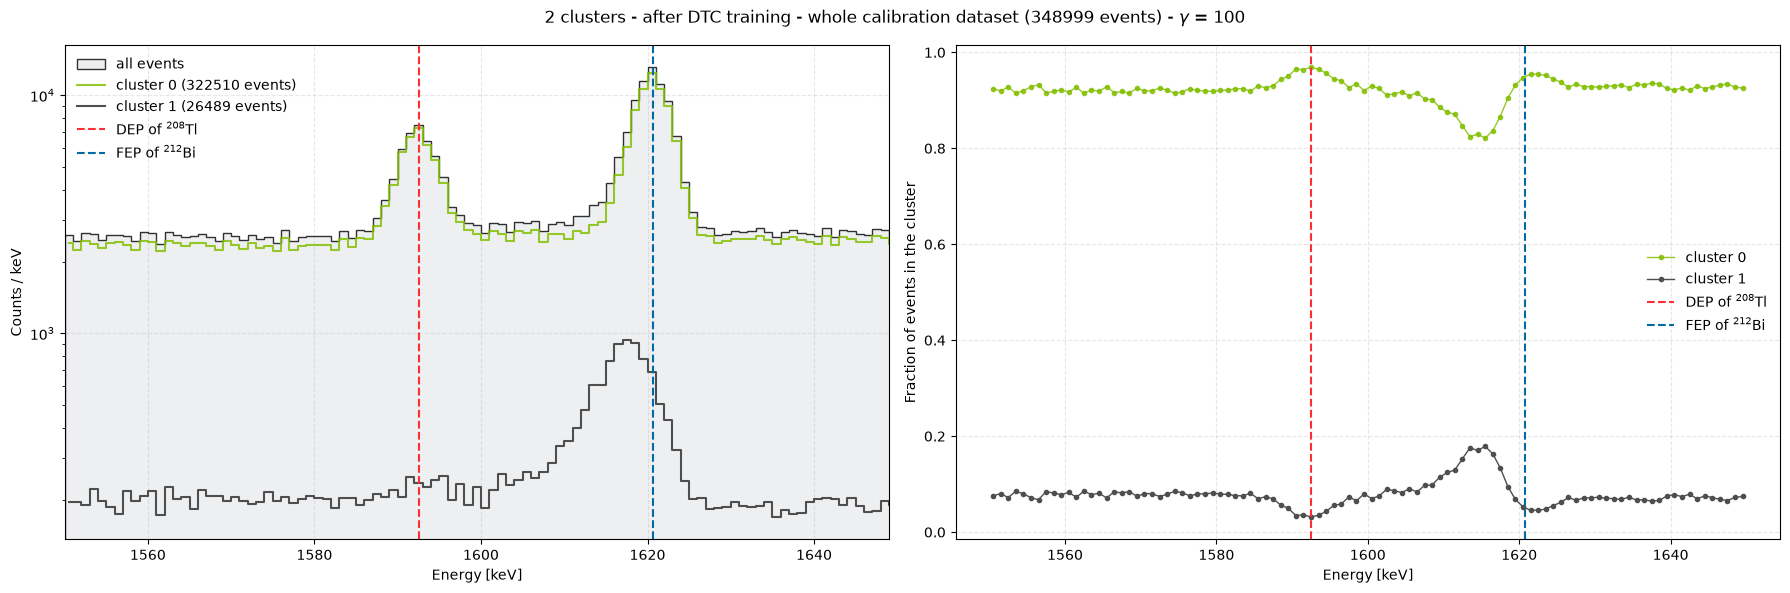

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.886 0.114]
[train] epoch 1/20 - train: -785.5847  val: -758.3256  events per cluster: [0.808 0.192]  changes: 0.0789
        NLL: -805.52   KL: 0.0199
[train] epoch 2/20 - train: -722.2177  val: -702.9021  events per cluster: [0.53 0.47]  changes: 0.2779
        NLL: -779.43   KL: 0.0572
[train] epoch 3/20 - train: -695.9343  val: -694.6804  events per cluster: [0.505 0.495]  changes: 0.0303
        NLL: -770.27   KL: 0.0743
[train] epoch 4/20 - train: -691.0162  val: -694.4668  events per cluster: [0.486 0.514]  changes: 0.0195
        NLL: -768.76   KL: 0.0777
[train] epoch 5/20 - train: -691.7290  val: -697.8291  events per cluster: [0.489 0.511]  changes: 0.0087
        NLL: -769.33   KL: 0.0776
[train] epoch 6/20 - train: -694.3799  val: -694.2219  events per cluster: [0.478 0.522]  changes: 0.0107
       

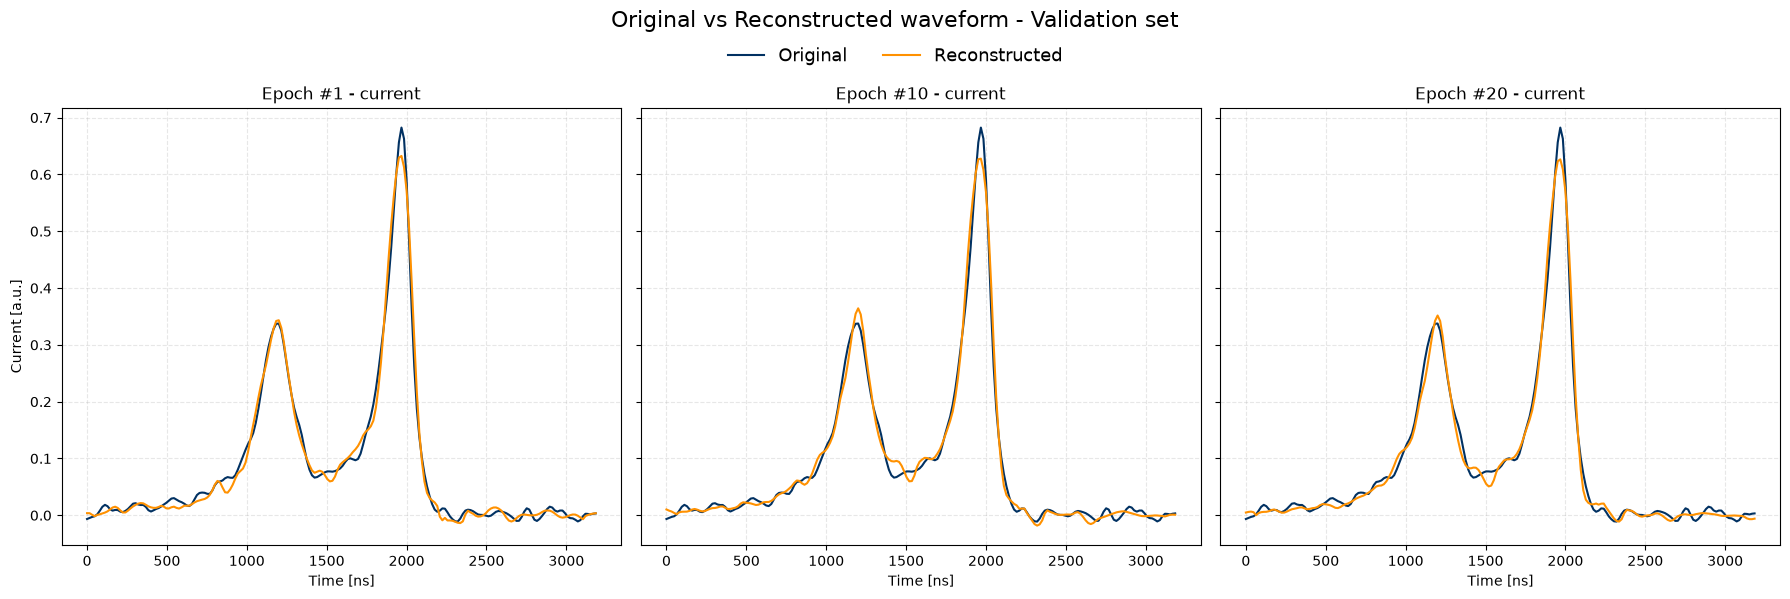

[euclidean, gamma=1000, 2 clusters] events that changed cluster with the training: 0.4558


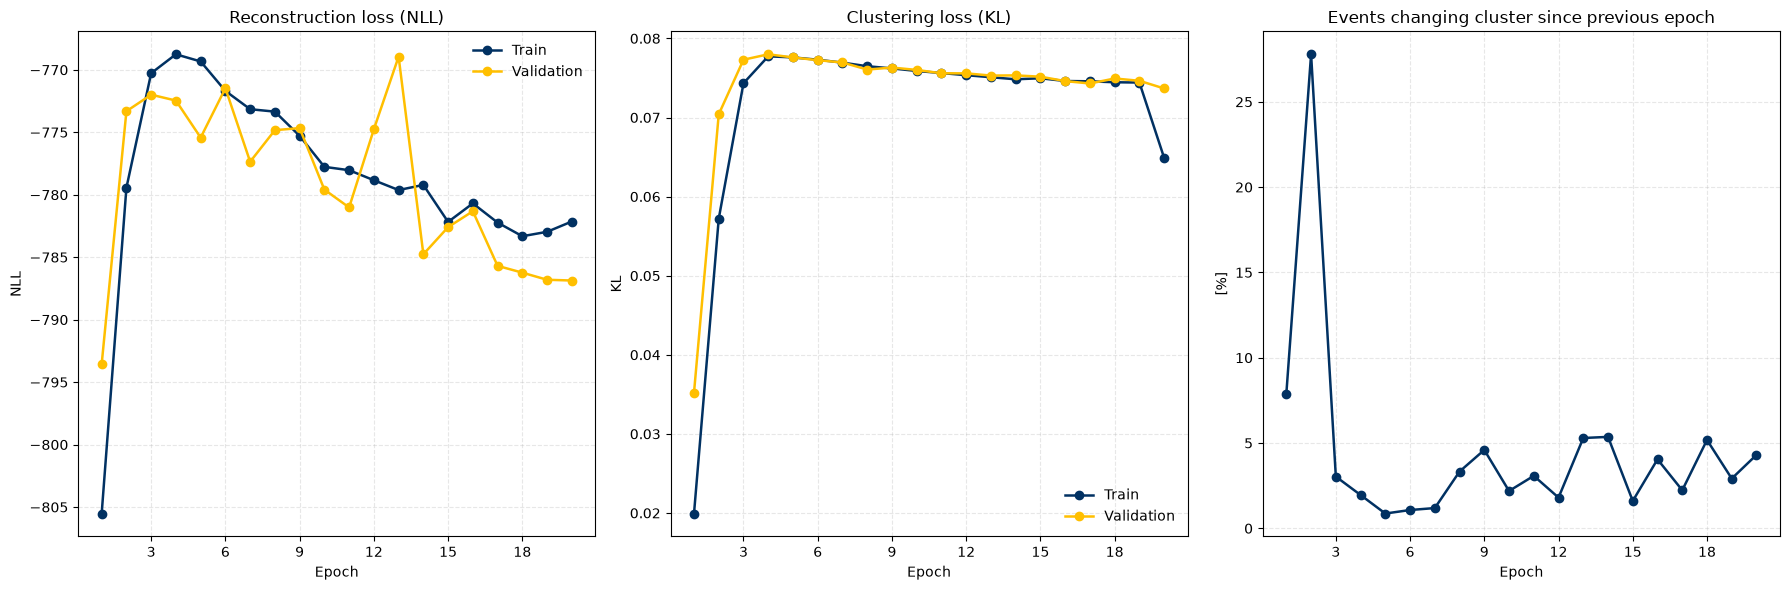

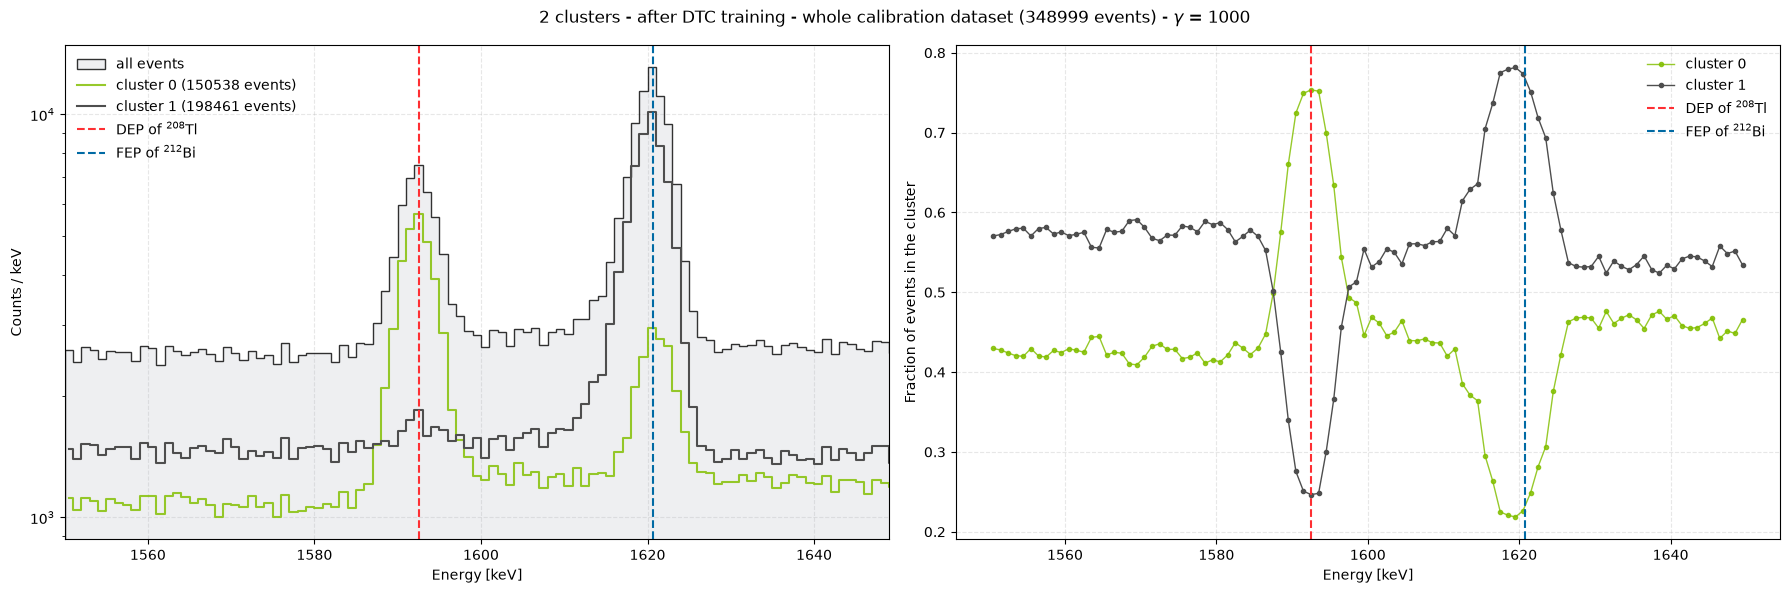

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.886 0.114]
[train] epoch 1/20 - train: 73.4607  val: 82.7829  events per cluster: [0.57 0.43]  changes: 0.3195
        NLL: -597.22   KL: 0.0671
[train] epoch 2/20 - train: 58.3824  val: 19.0839  events per cluster: [0.636 0.364]  changes: 0.0661
        NLL: -635.02   KL: 0.0693
[train] epoch 3/20 - train: 29.0789  val: 3.3846  events per cluster: [0.584 0.416]  changes: 0.0517
        NLL: -654.55   KL: 0.0684
[train] epoch 4/20 - train: 16.1335  val: 16.7479  events per cluster: [0.509 0.491]  changes: 0.0774
        NLL: -656.53   KL: 0.0673
[train] epoch 5/20 - train: -361.6615  val: -2.7355  events per cluster: [0.557 0.443]  changes: 0.0532
        NLL: -670.11   KL: 0.0308
[train] epoch 6/20 - train: -6.9728  val: -7.1835  events per cluster: [0.549 0.451]  changes: 0.0211
        NLL: -683.42   KL: 0.0

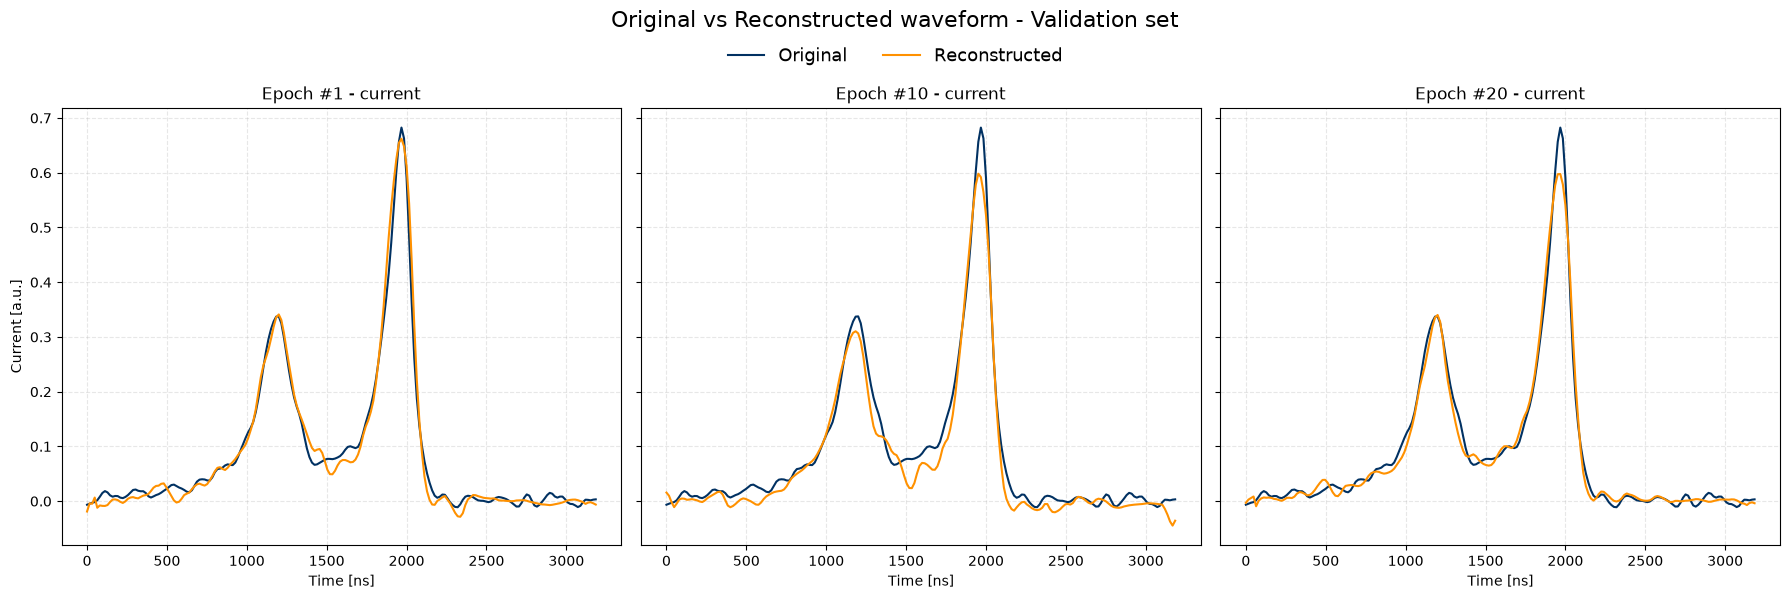

[euclidean, gamma=10000, 2 clusters] events that changed cluster with the training: 0.2434


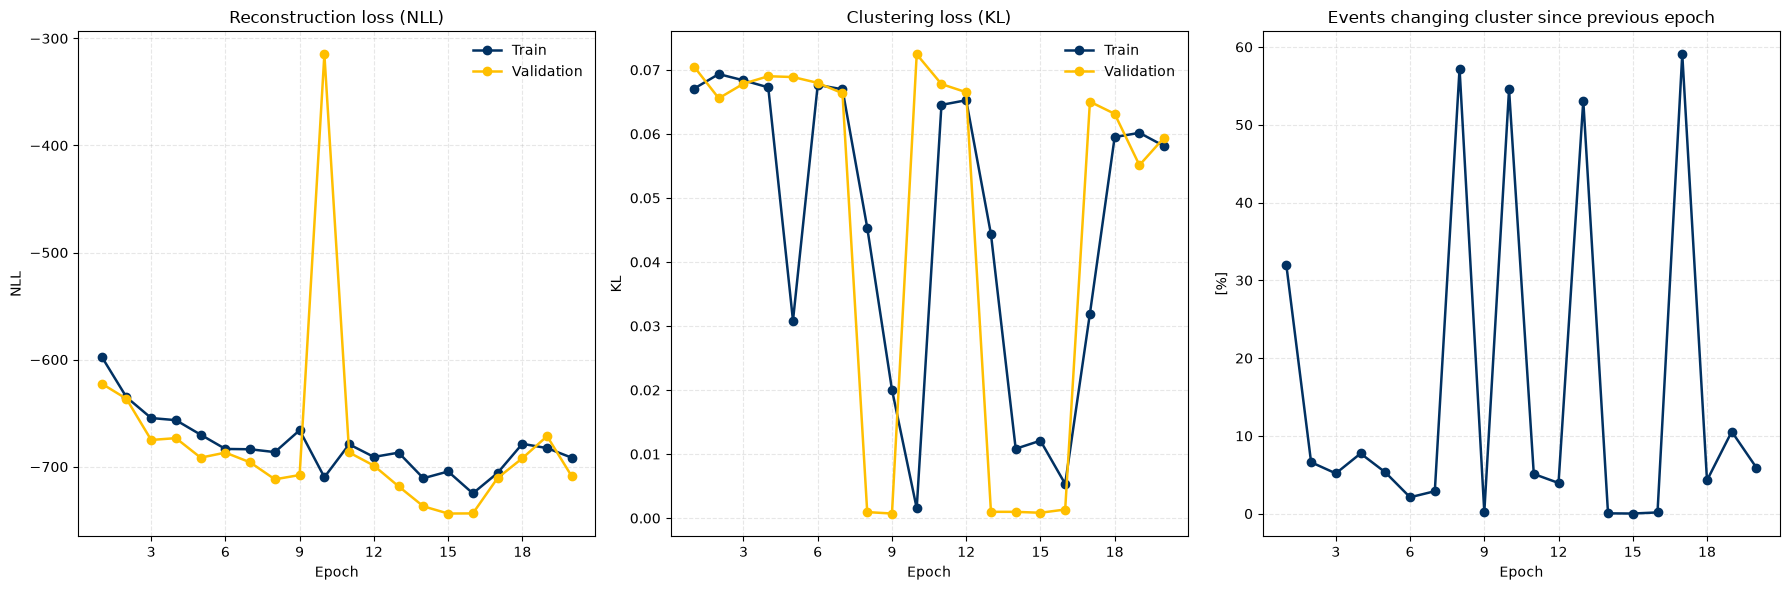

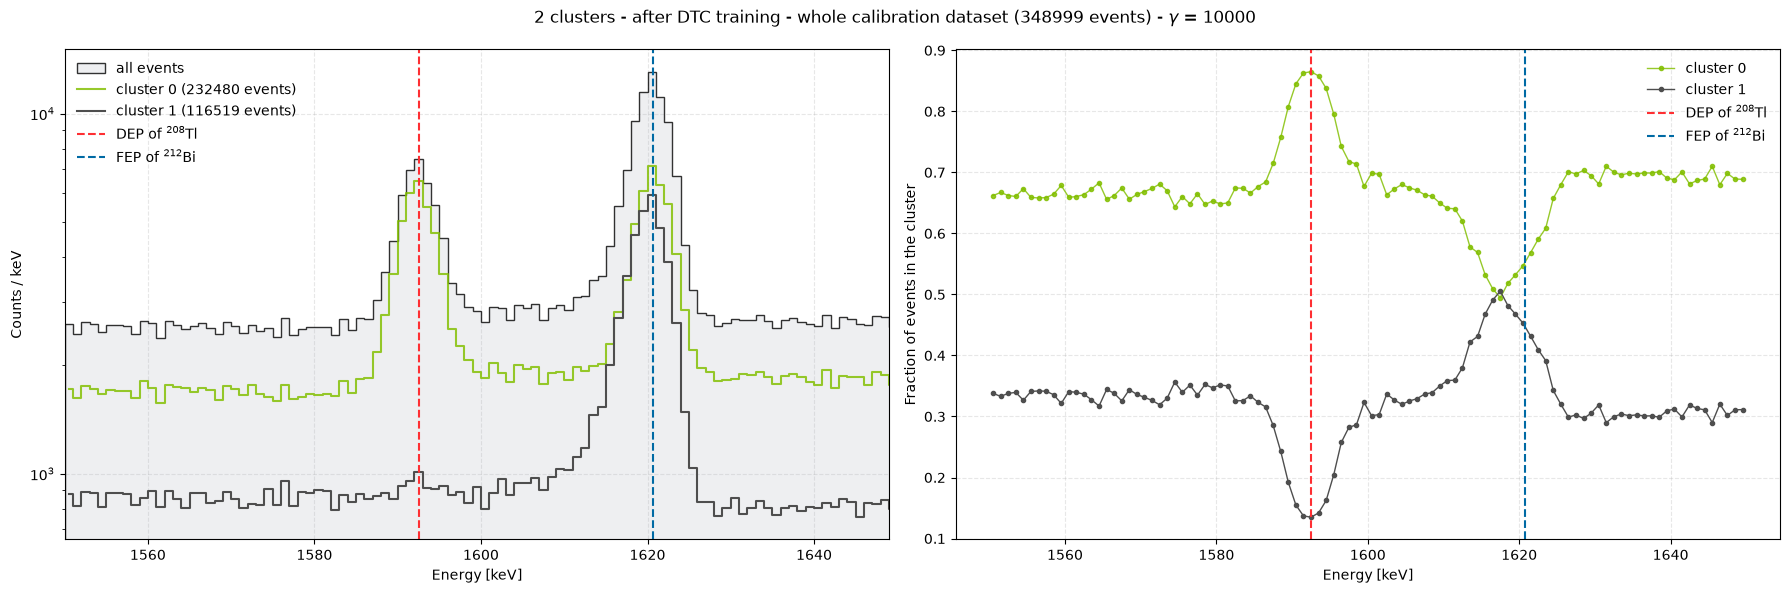

In [14]:
pf.TAG = SCAN_METRIC
scan_gamma = {}
for g in SCAN_GAMMAS:
    pf.PREFIX = f"scan_{SCAN_METRIC}_gamma{g}_"           # also the reconstruction plot made inside DTC.training
    scan_gamma[g] = cluster_run(N_CLUSTERS, METRICS[SCAN_METRIC], gamma=g, epochs=SCAN_EPOCHS)
    plot_energy_and_history(scan_gamma[g], pf.PREFIX, label=f"$\\gamma$ = {g}")

In [15]:
rows = []
for g, r in scan_gamma.items():
    h, y = r['model'].history, r['y']
    s = sse_like(y, N_CLUSTERS)
    keep = y == s
    rows.append({'gamma': g,
                 'NLL validation': h['nll_val'][-1],
                 'NLL change vs pretrain': h['nll_val'][-1] - pre_val_l[-1],
                 'KL validation': h['kl_val'][-1],
                 'gamma x KL': g * h['kl_val'][-1],
                 'moved from KMeans [%]': 100 * (r['y_init'] != y).mean(),
                 'changes last epoch [%]': 100 * h['changes'][-1],
                 'SSE-like kept [%]': 100 * keep.mean(),
                 'DEP kept [%]': 100 * keep[in_dep].mean(),
                 'FEP kept [%]': 100 * keep[in_fep].mean()})
save_table(pd.DataFrame(rows).set_index('gamma'), f'table_scan_{SCAN_METRIC}_gamma')

,NLL validation,NLL change vs pretrain,KL validation,gamma x KL,moved from KMeans [%],changes last epoch [%],SSE-like kept [%],DEP kept [%],FEP kept [%]
gamma,,,,,,,,,
10,-818.43,-3.60,0.01,0.13,4.22,0.13,92.92,95.57,92.18
100,-818.13,-3.30,0.02,1.54,3.71,0.16,92.41,95.27,91.64
1000,-786.86,27.96,0.07,73.67,45.58,4.31,43.13,65.65,27.50
10000,-709.07,105.75,0.06,594.29,24.34,5.90,66.61,80.77,56.37


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_gamma.csv | table_scan_eucl_gamma.tex


# 2b. SCAN OF THE NUMBER OF CLUSTERS (Euclidean, 30 epochs, $\gamma$ = 1000)
Files `scan_eucl_<K>cl_...`. The run with `N_CLUSTERS` clusters and `GAMMA` is taken from the $\gamma$ scan, not trained again.
Tables: losses per number of clusters, and composition of every cluster (size, fraction of the DEP and of the FEP events).

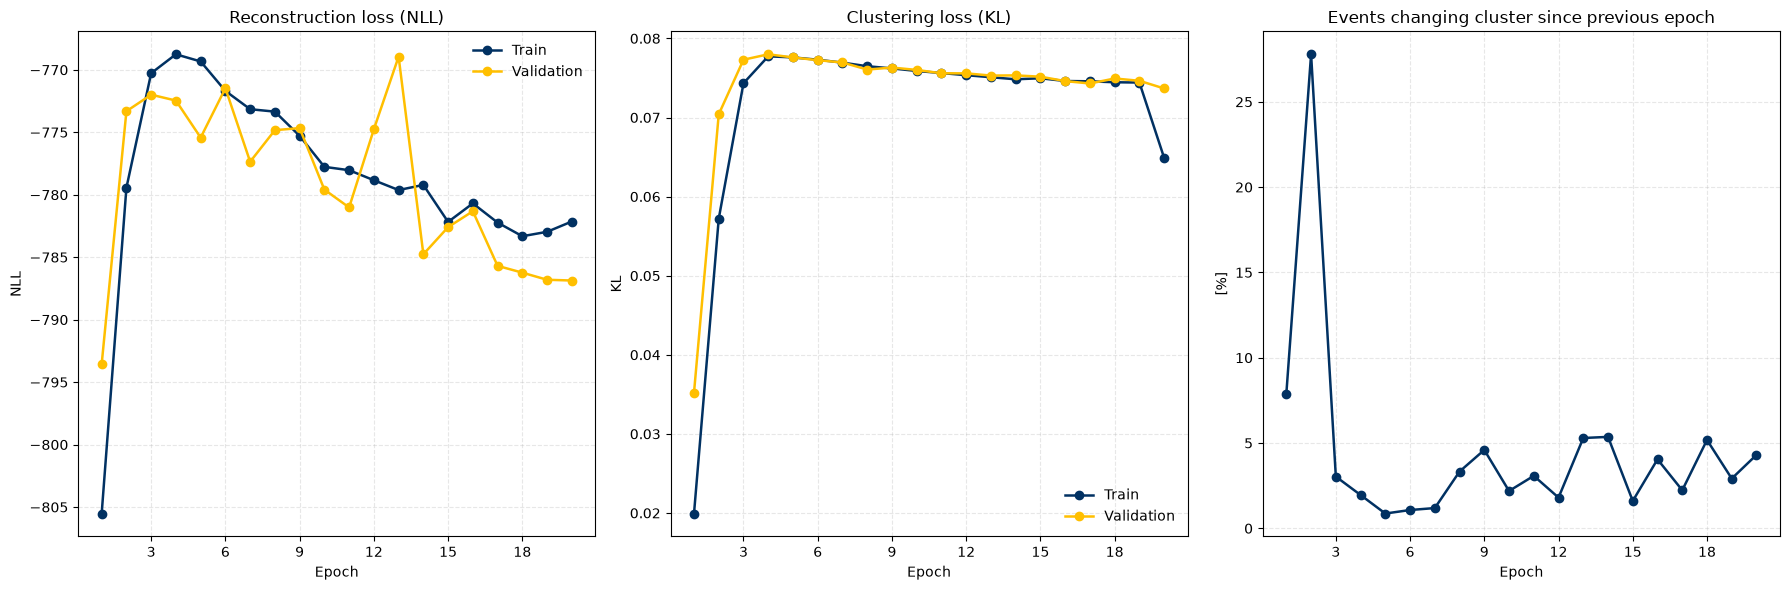

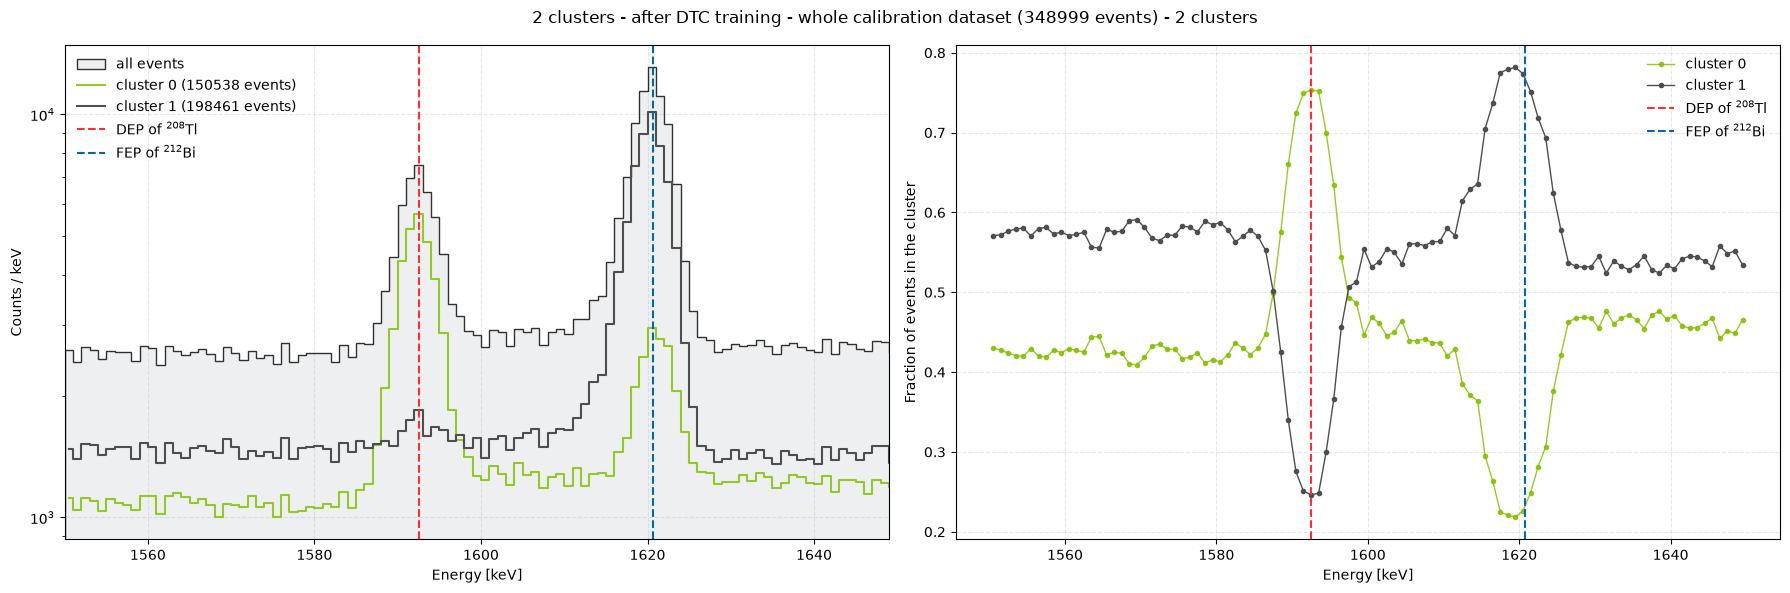

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.804 0.055 0.141]
[train] epoch 1/20 - train: -784.7366  val: -757.6802  events per cluster: [0.    0.306 0.694]  changes: 0.9452
        NLL: -805.71   KL: 0.0210
[train] epoch 2/20 - train: -722.9756  val: -702.1260  events per cluster: [0.    0.497 0.503]  changes: 0.1905
        NLL: -780.09   KL: 0.0571
[train] epoch 3/20 - train: -698.3083  val: -695.9088  events per cluster: [0.    0.489 0.511]  changes: 0.0132
        NLL: -771.79   KL: 0.0735
[train] epoch 4/20 - train: -691.0703  val: -691.1907  events per cluster: [0.    0.508 0.492]  changes: 0.0239
        NLL: -768.77   KL: 0.0777
[train] epoch 5/20 - train: -692.1894  val: -691.1649  events per cluster: [0.    0.499 0.501]  changes: 0.0143
        NLL: -769.87   KL: 0.0777
[train] epoch 6/20 - train: -698.2017  val: -663.5301  events per cluster: 

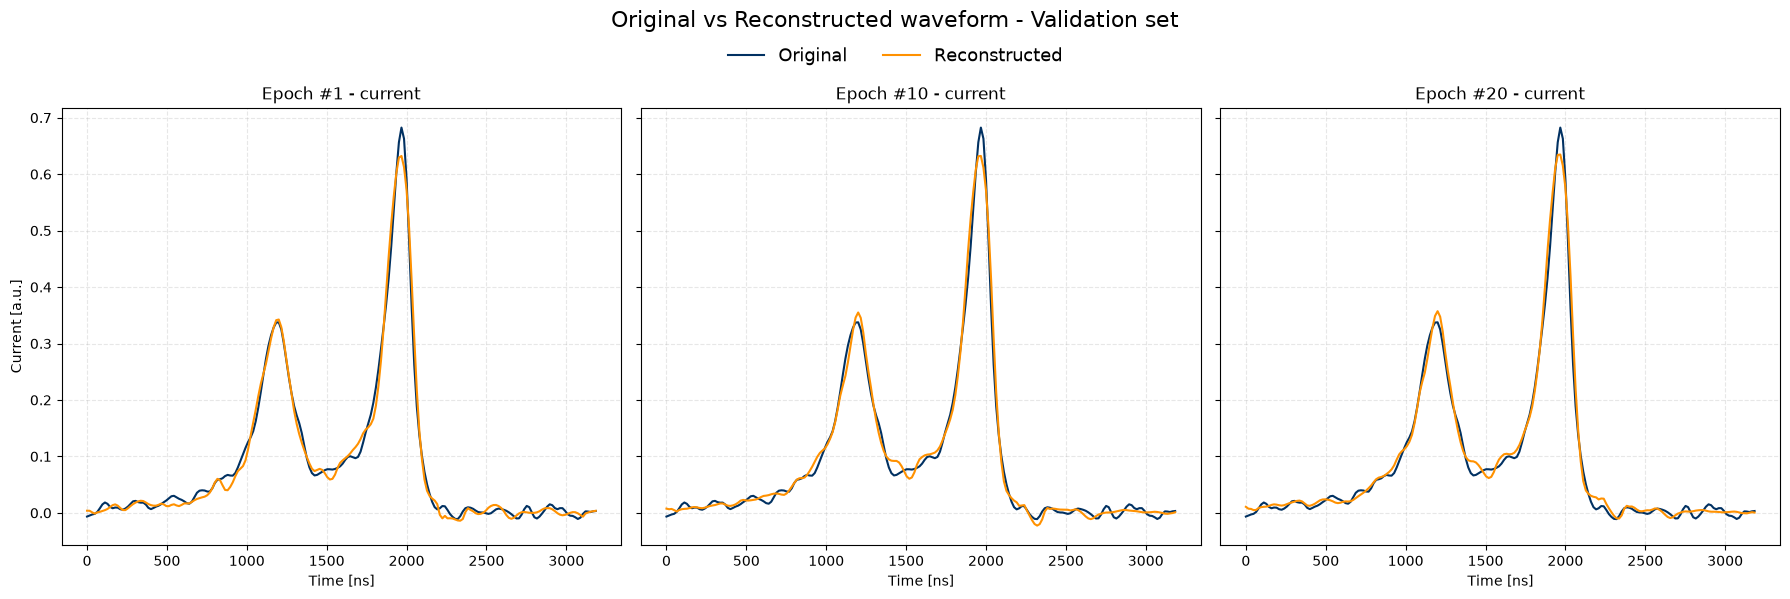

[euclidean, gamma=1000, 3 clusters] events that changed cluster with the training: 0.9448


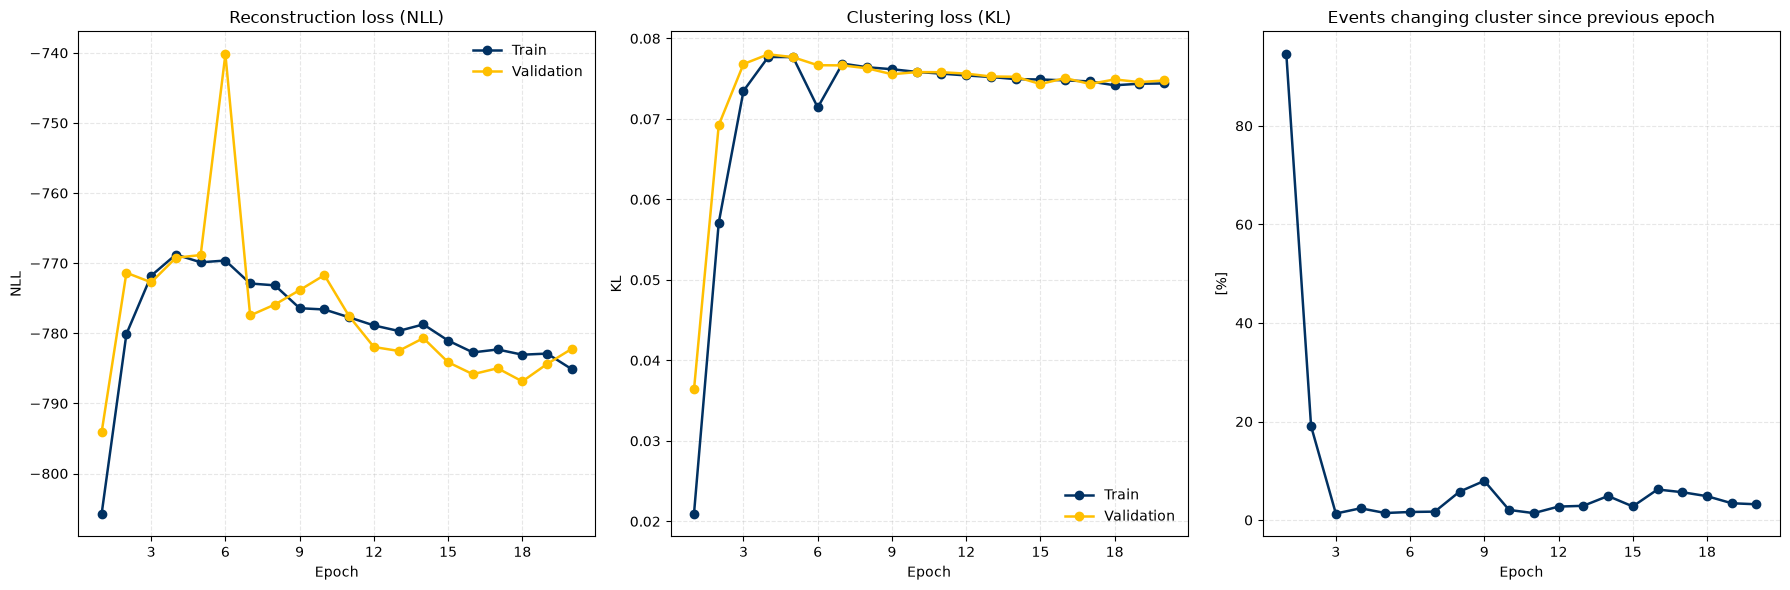

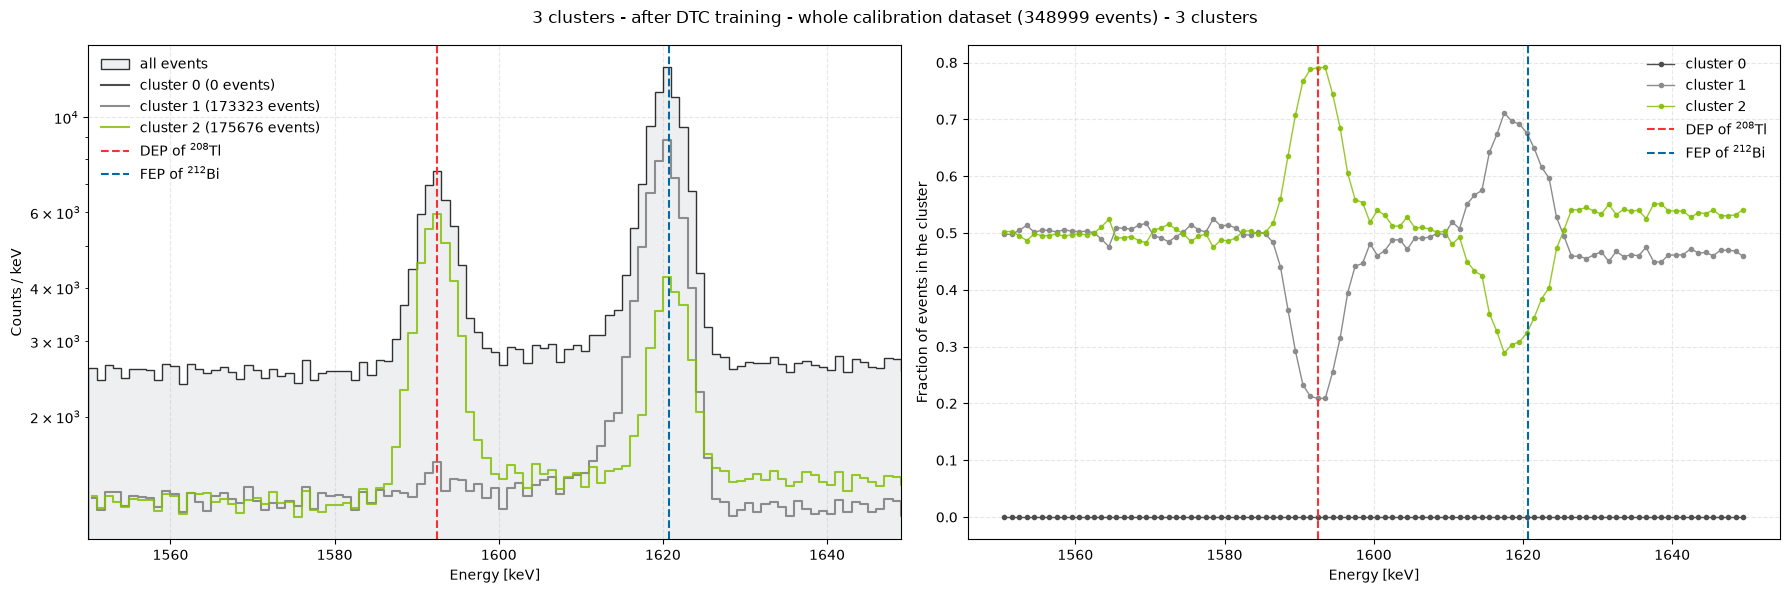

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.177 0.032 0.727 0.063]
[train] epoch 1/20 - train: -785.5904  val: -759.2530  events per cluster: [0.    0.179 0.809 0.012]  changes: 0.2414
        NLL: -805.55   KL: 0.0200
[train] epoch 2/20 - train: -722.3879  val: -700.8416  events per cluster: [0.532 0.467 0.    0.001]  changes: 0.8199
        NLL: -779.59   KL: 0.0572
[train] epoch 3/20 - train: -695.6864  val: -693.9123  events per cluster: [0.386 0.026 0.123 0.465]  changes: 0.5874
        NLL: -770.08   KL: 0.0744
[train] epoch 4/20 - train: -690.9607  val: -695.4476  events per cluster: [0.48  0.491 0.008 0.021]  changes: 0.5843
        NLL: -768.75   KL: 0.0778
[train] epoch 5/20 - train: -690.7999  val: -681.4735  events per cluster: [0.423 0.489 0.086 0.002]  changes: 0.1317
        NLL: -768.41   KL: 0.0776
[train] epoch 6/20 - train: -694.2398  

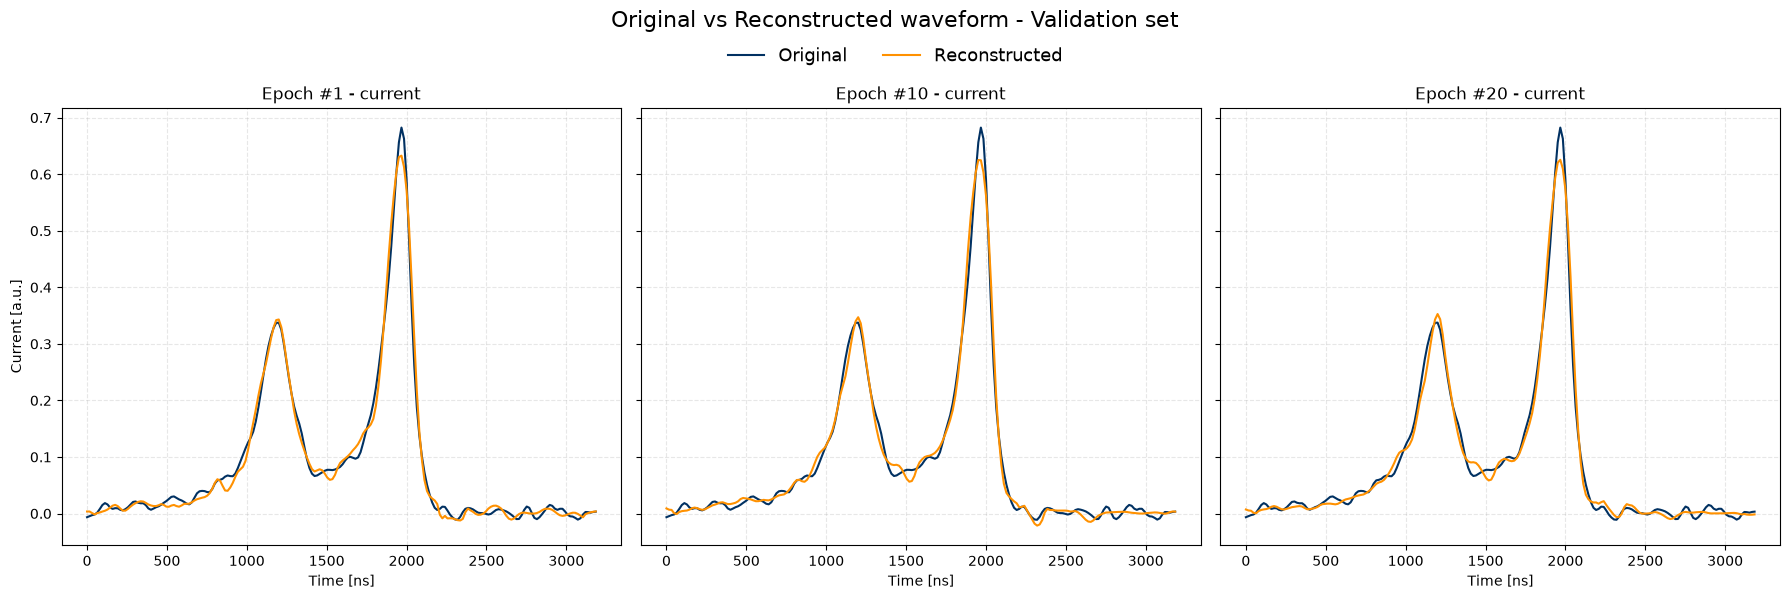

[euclidean, gamma=1000, 4 clusters] events that changed cluster with the training: 0.9685


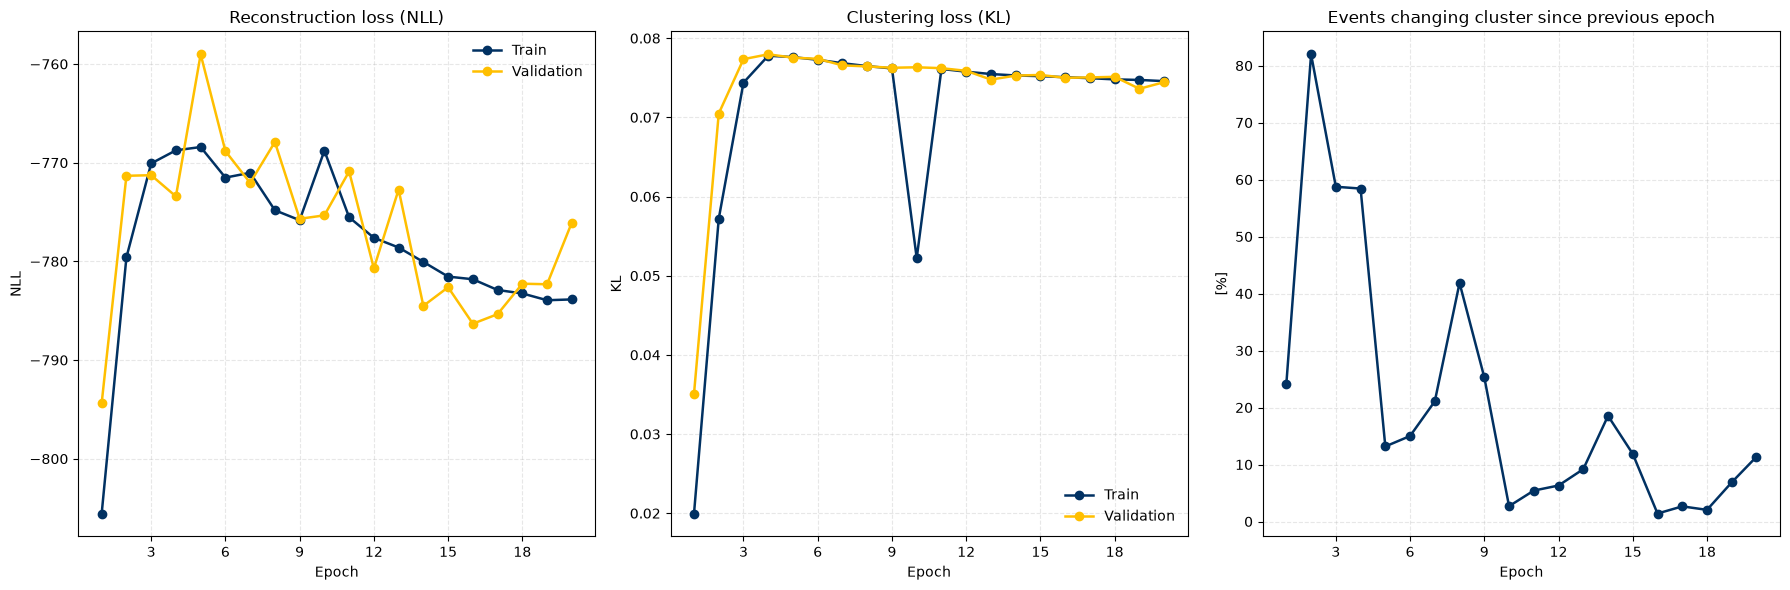

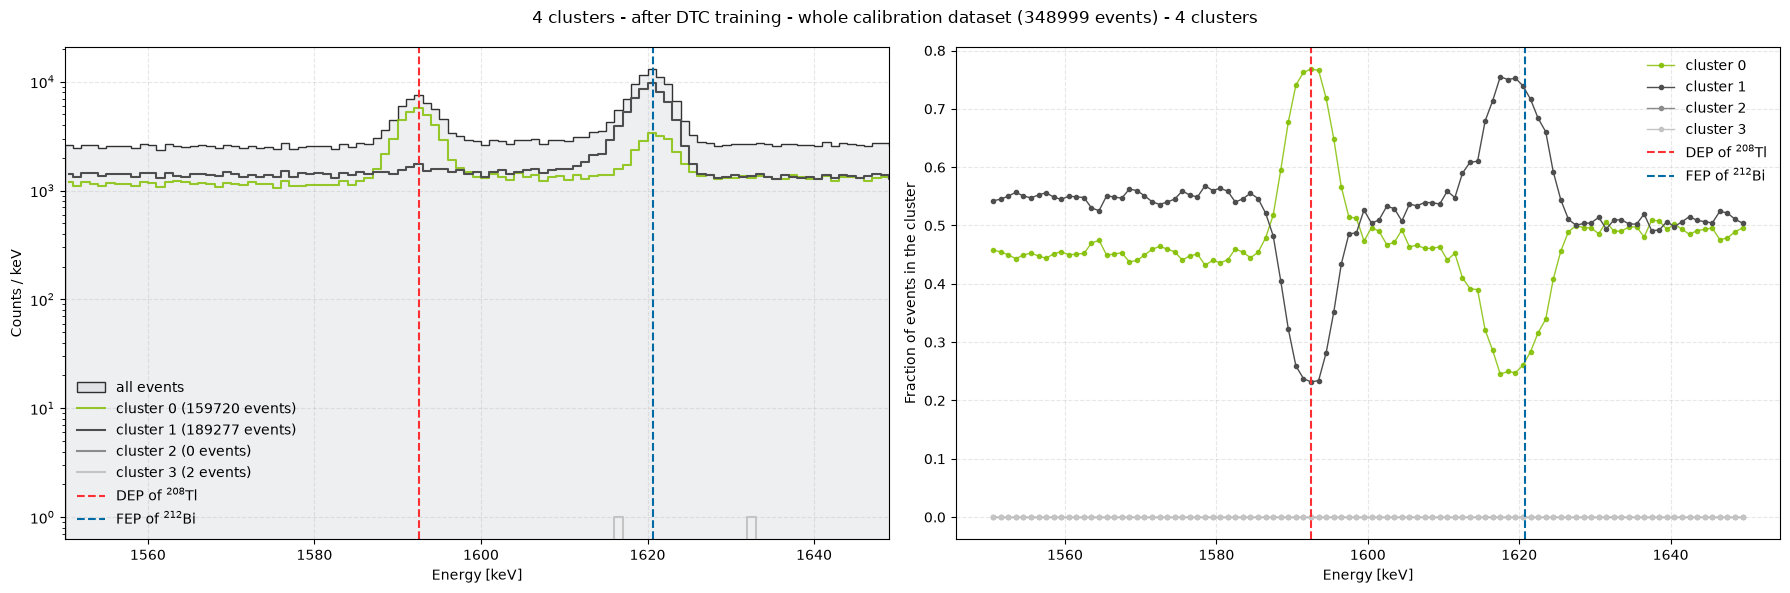

In [16]:
pf.TAG = SCAN_METRIC
scan_k = {}
for k in SCAN_CLUSTERS:
    if k == N_CLUSTERS and GAMMA in scan_gamma:
        scan_k[k] = scan_gamma[GAMMA]                       # same run: no need to train it again
    else:
        pf.PREFIX = f"scan_{SCAN_METRIC}_"                   # files scan_eucl_<K>cl_...
        scan_k[k] = cluster_run(k, METRICS[SCAN_METRIC], gamma=GAMMA, epochs=SCAN_EPOCHS)
    plot_energy_and_history(scan_k[k], f"scan_{SCAN_METRIC}_", label=f"{k} clusters")

In [17]:
loss_rows, comp_rows = [], []
for k, r in scan_k.items():
    h, y = r['model'].history, r['y']
    loss_rows.append({'clusters': k,
                      'NLL validation': h['nll_val'][-1],
                      'NLL change vs pretrain': h['nll_val'][-1] - pre_val_l[-1],
                      'KL validation': h['kl_val'][-1],
                      'moved from KMeans [%]': 100 * (r['y_init'] != y).mean(),
                      'changes last epoch [%]': 100 * h['changes'][-1]})
    size, dep_f, fep_f = composition(y, k)
    for j in range(k):
        comp_rows.append({'clusters / cluster': f"{k} / {j}", 'events [%]': 100 * size[j],
                          'DEP events in the cluster [%]': 100 * dep_f[j],
                          'FEP events in the cluster [%]': 100 * fep_f[j]})
save_table(pd.DataFrame(loss_rows).set_index('clusters'), f'table_scan_{SCAN_METRIC}_clusters_losses')
save_table(pd.DataFrame(comp_rows).set_index('clusters / cluster'), f'table_scan_{SCAN_METRIC}_clusters_composition')

,NLL validation,NLL change vs pretrain,KL validation,moved from KMeans [%],changes last epoch [%]
clusters,,,,,
2,-786.86,27.96,0.07,45.58,4.31
3,-782.21,32.61,0.07,94.48,3.20
4,-776.07,38.76,0.07,96.85,11.37


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_clusters_losses.csv | table_scan_eucl_clusters_losses.tex


,events [%],DEP events in the cluster [%],FEP events in the cluster [%]
clusters / cluster,,,
2 / 0,43.13,65.65,27.50
2 / 1,56.87,34.35,72.50
3 / 0,0.00,0.00,0.00
3 / 1,49.66,29.51,63.86
3 / 2,50.34,70.49,36.14
4 / 0,45.77,67.41,30.49
4 / 1,54.23,32.59,69.51
4 / 2,0.00,0.00,0.00
4 / 3,0.00,0.00,0.00


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_scan_eucl_clusters_composition.csv | table_scan_eucl_clusters_composition.tex


# 3. FINAL RUNS: ACF, EUCLIDEAN, CID
2 clusters, $\gamma$ = 1000, `TRAINING_EPOCHS` epochs. For every metric (files `<metric>_...`):
- reconstruction after the training (made inside `DTC.training`) and training history;
- table of the losses of every epoch;
- clusters vs energy and A/E + rise time on the **training**, **validation** and **test** set;
- weights and bundle saved in `finalmodels/` (format read by DTC-allMETRICS and by the 2$\nu\beta\beta$ analysis).

In [18]:
def run_final(tag):
    
    metric = METRICS[tag]
    pf.TAG, pf.PREFIX = tag, f"{tag}_"
    run = cluster_run(N_CLUSTERS, metric, gamma=GAMMA, epochs=TRAINING_EPOCHS)
    y = run['y']
    colors = pf.cluster_colors(y, energy, N_CLUSTERS)       # from ALL the events: same colors in every plot
    
    pf.plot_training_history(run['model'].history, name=f"{N_CLUSTERS}cl_training_history")
    for split in ('train', 'val', 'test'):
        idx = data[f'idx_{split}']
        title = pf._title(N_CLUSTERS, split, len(idx))
        pf.plot_clusters_vs_energy(y[idx], energy[idx], N_CLUSTERS, title=title,
                                   name=f"{N_CLUSTERS}cl_energy_{split}", colors=colors)
        pf.plot_cluster_variables(y[idx], data['AoE'][idx], data['rise_time'][idx], N_CLUSTERS, title=title,
                                  name=f"{N_CLUSTERS}cl_AoE_risetime_{split}", colors=colors)
    
    save_table(training_table(run), f'table_{tag}_training_losses')
    
    # SSE-like cluster and saving (same formats as before)
    run['sse_cluster'] = s = sse_like(y, N_CLUSTERS)
    _, dep_f, fep_f = composition(y, N_CLUSTERS)
    print(f"{metric}: DEP per cluster {np.round(dep_f, 3)} | FEP per cluster {np.round(fep_f, 3)} -> SSE-like cluster = {s}")
    
    base = os.path.join(OUT_DIR, f"dtc{N_CLUSTERS}_{metric}_gamma{GAMMA}_{TRAINING_EPOCHS}ep")
    model = run['model']
    torch.save({'state_dict': model.state_dict(), 'sse_cluster': s}, base + ".pth")
    bundle = dict(
        state_dict=model.state_dict(),
        model_kwargs=dict(input_length=int(data['waves'].shape[-1]), pool_size=10, n_clusters=N_CLUSTERS,
                          distance_metric=metric, use_charge=use_charge),
        config={k: (v.item() if hasattr(v, 'item') else v) for k, v in data['config'].items()},
        scale_factor=float(data['scale_factor']),
        charge_scale_factor=float(data['charge_scale_factor']),
        channels=int(data['channels']),
        wfcleaning_file=os.path.abspath(preliminary.wfcleaning.__file__),
        cleaning_kwargs=dict(baseline_points=300, n_sigmas=3, pre_trigger_points=75, post_trigger_points=124),
        dep_frac=dep_f, fep_frac=fep_f, sse_cluster=s,
        gamma=GAMMA, epochs=TRAINING_EPOCHS, pretraining_epochs=PRETRAINING_EPOCHS, tae_file=os.path.abspath(TAE_PATH),
    )
    torch.save(bundle, base + "_bundle.pth")
    print("saved:", os.path.abspath(base + ".pth"), "|", os.path.abspath(base + "_bundle.pth"))
    return run


runs = {}

#### ACF

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans
Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.915 0.085]
[train] epoch 1/20 - train: -806.0535  val: -804.5085  events per cluster: [0.337 0.663]  changes: 0.5836
        NLL: -810.83   KL: 0.0048
[train] epoch 2/20 - train: -791.2251  val: -751.4938  events per cluster: [0.567 0.433]  changes: 0.2375
        NLL: -805.36   KL: 0.0141
[train] epoch 3/20 - train: -709.7427  val: -697.5172  events per cluster: [0.512 0.488]  changes: 0.0652
        NLL: -770.92   KL: 0.0612
[train] epoch 4/20 - train: -692.5748  val: -695.3113  events per cluster: [0.495 0.505]  changes: 0.0172
        NLL: -766.55   KL: 0.0740
[train] epoch 5/20 - train: -691.6822  val: -694.3791  events per cluster: [0.492 0.508]  changes: 0.0053
        NLL: -768.15   KL: 0.0765
[train] epoch 6/20 - train: -691.2692  val: -690.6637  events per cluster: [0.519 0.481]  changes: 0.0274
     

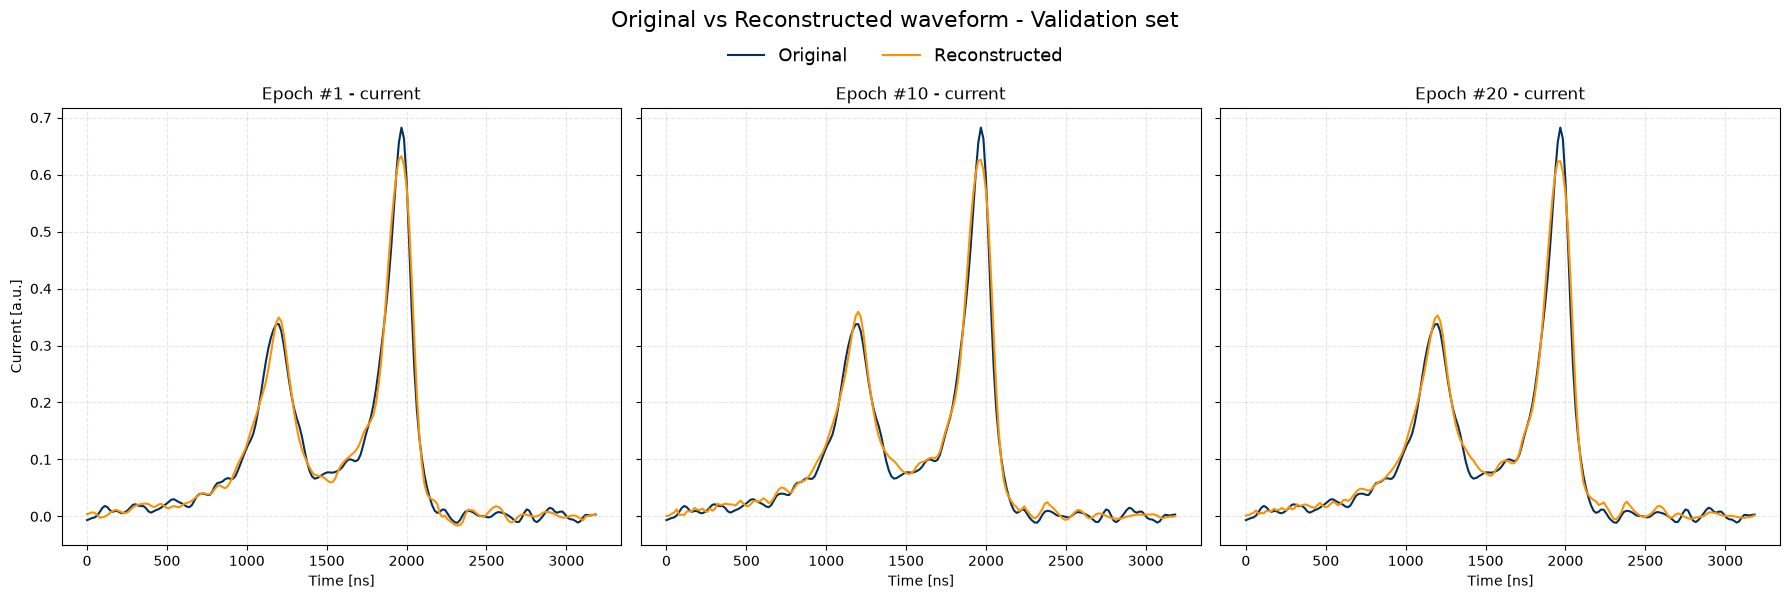

[acf, gamma=1000, 2 clusters] events that changed cluster with the training: 0.3905


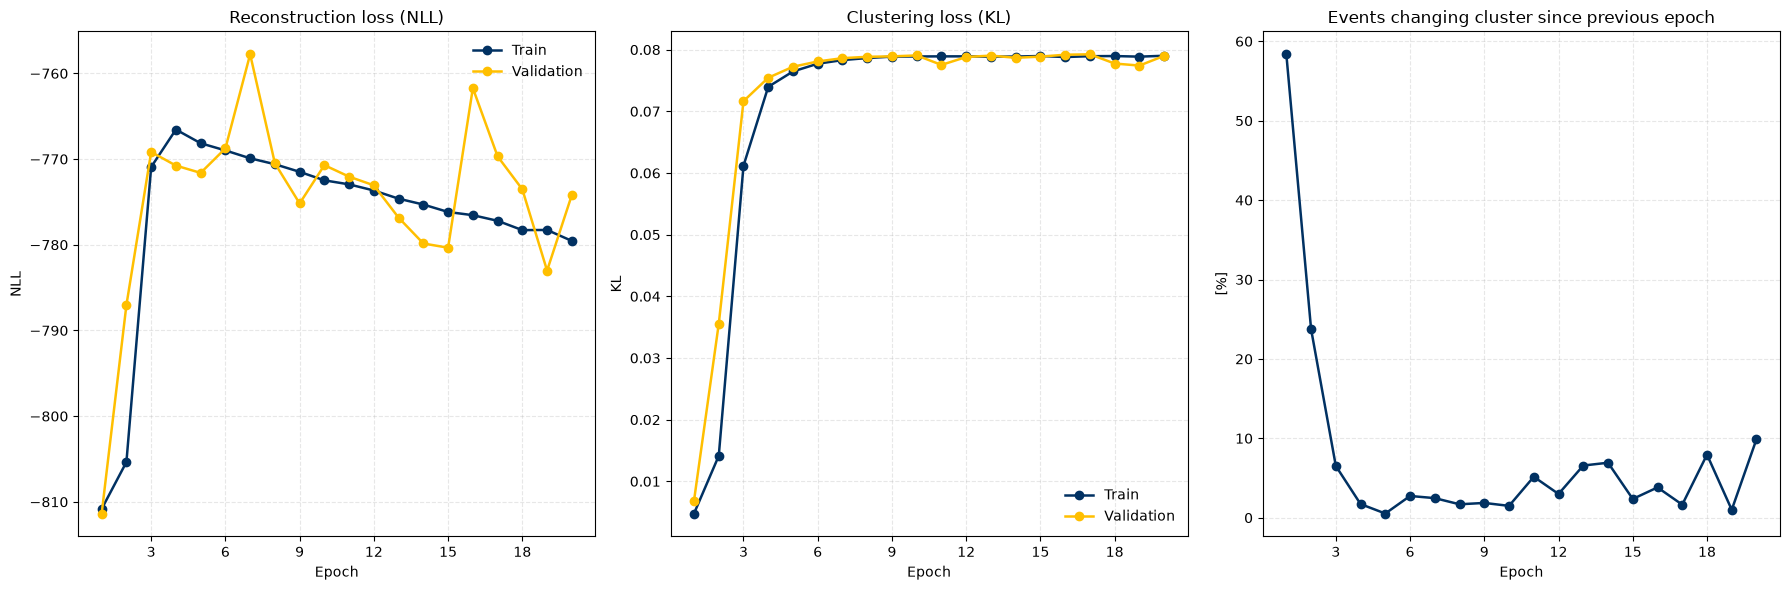

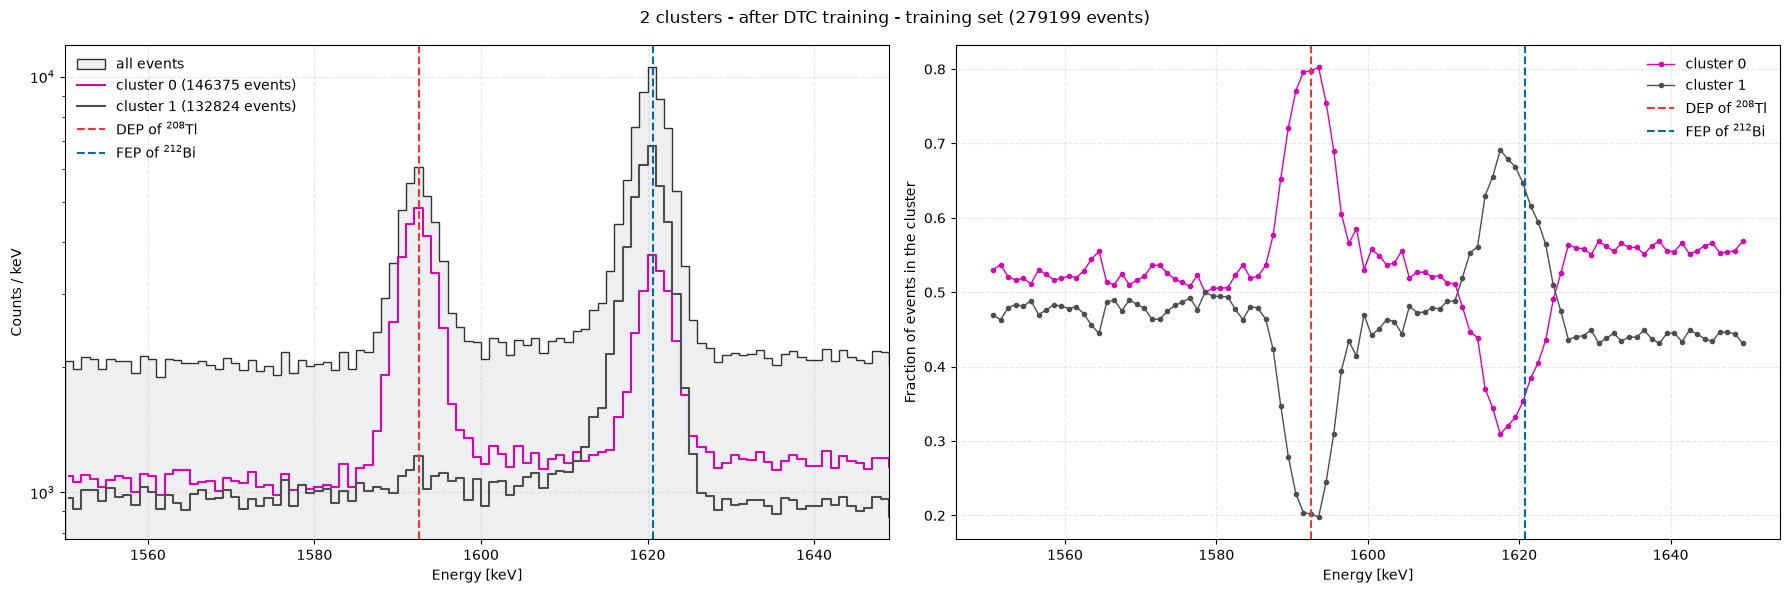

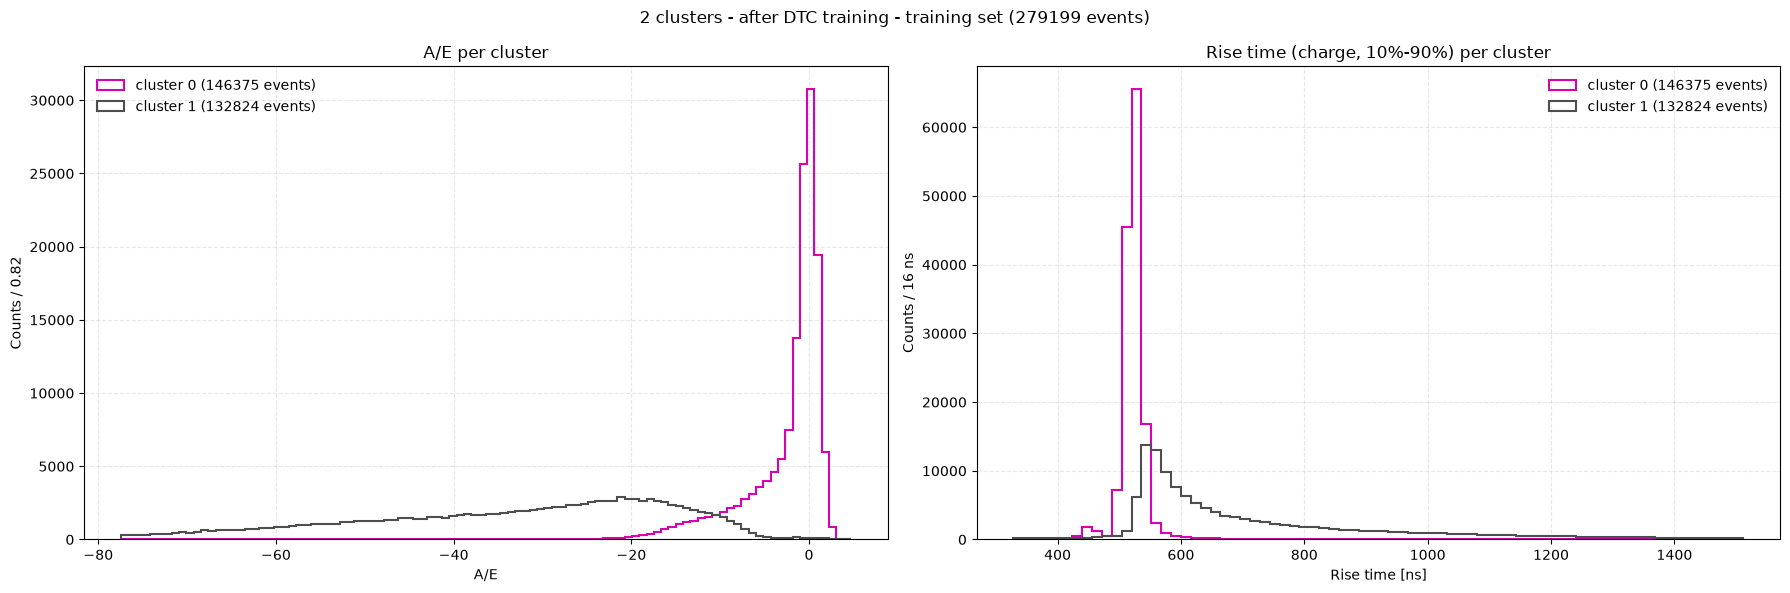

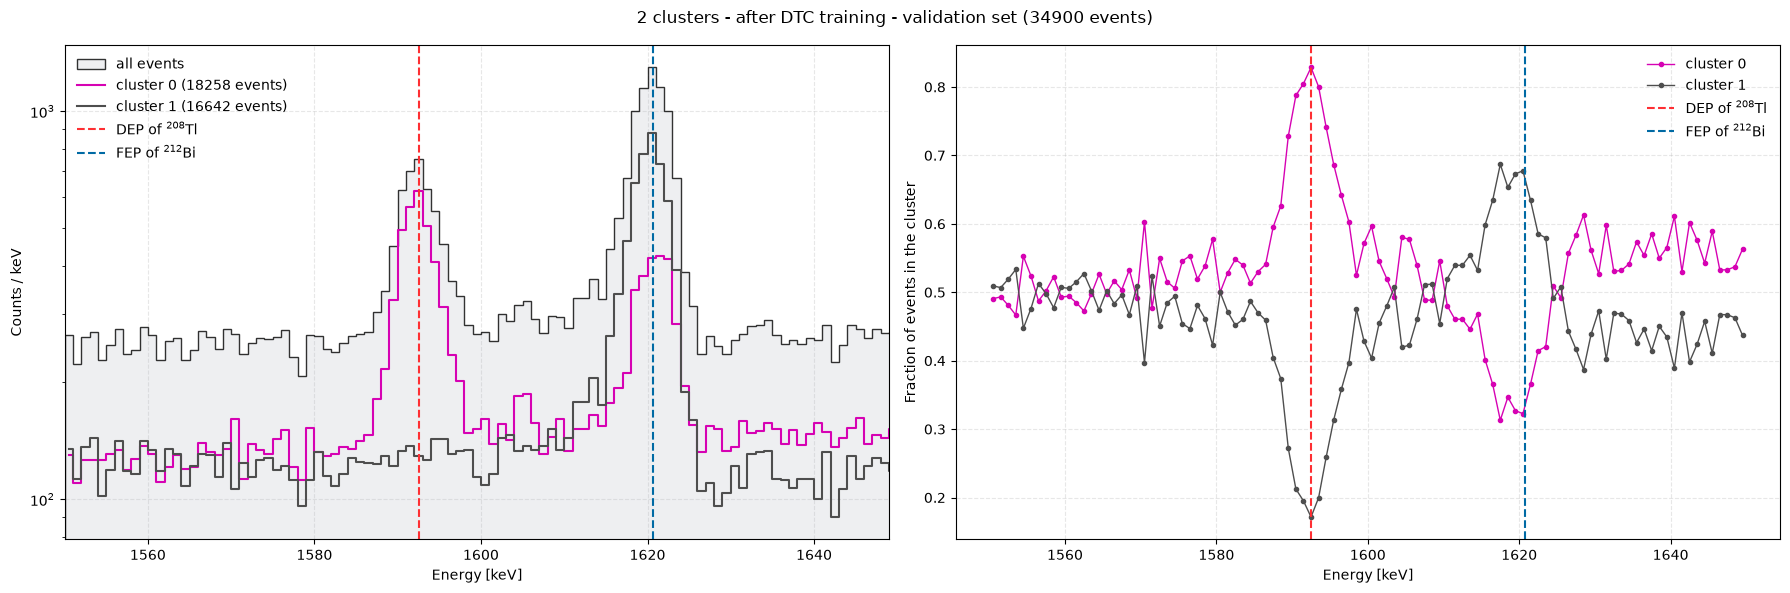

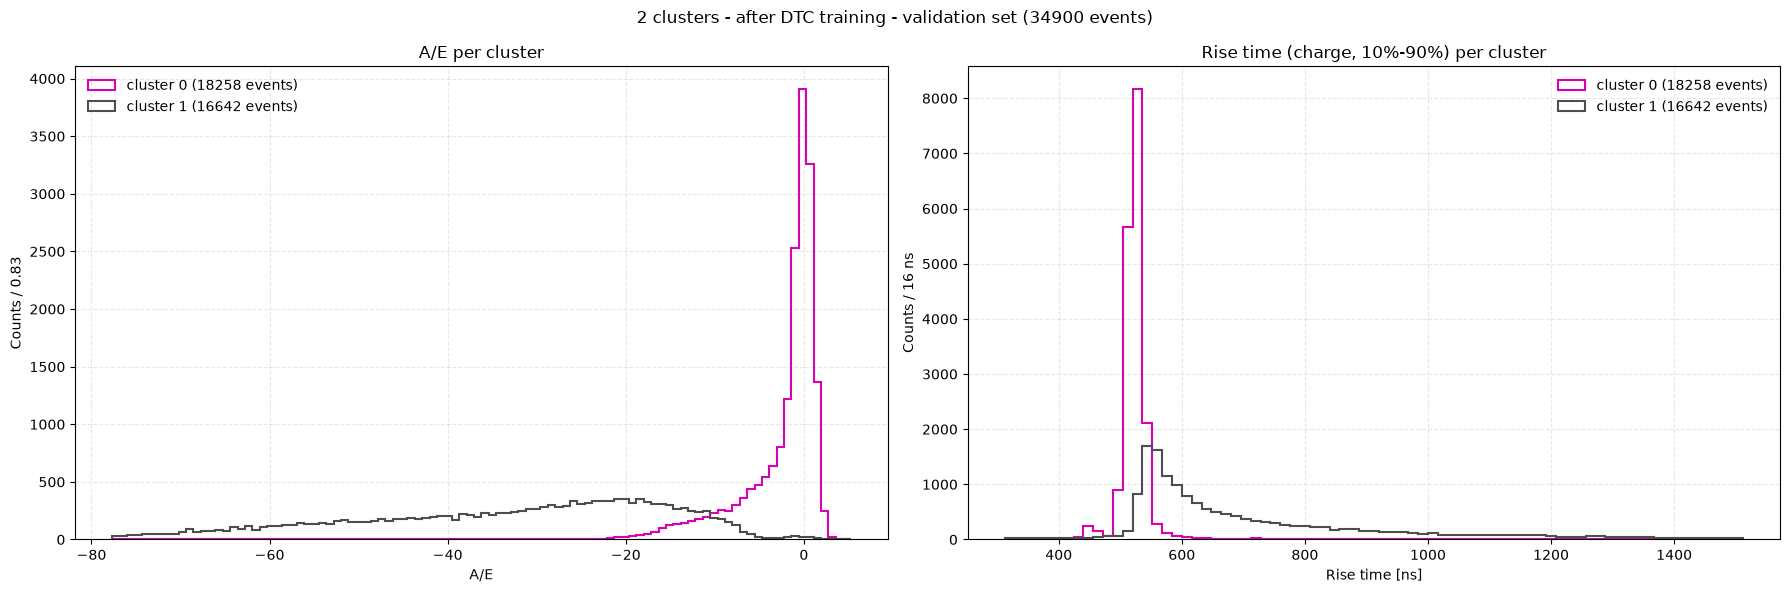

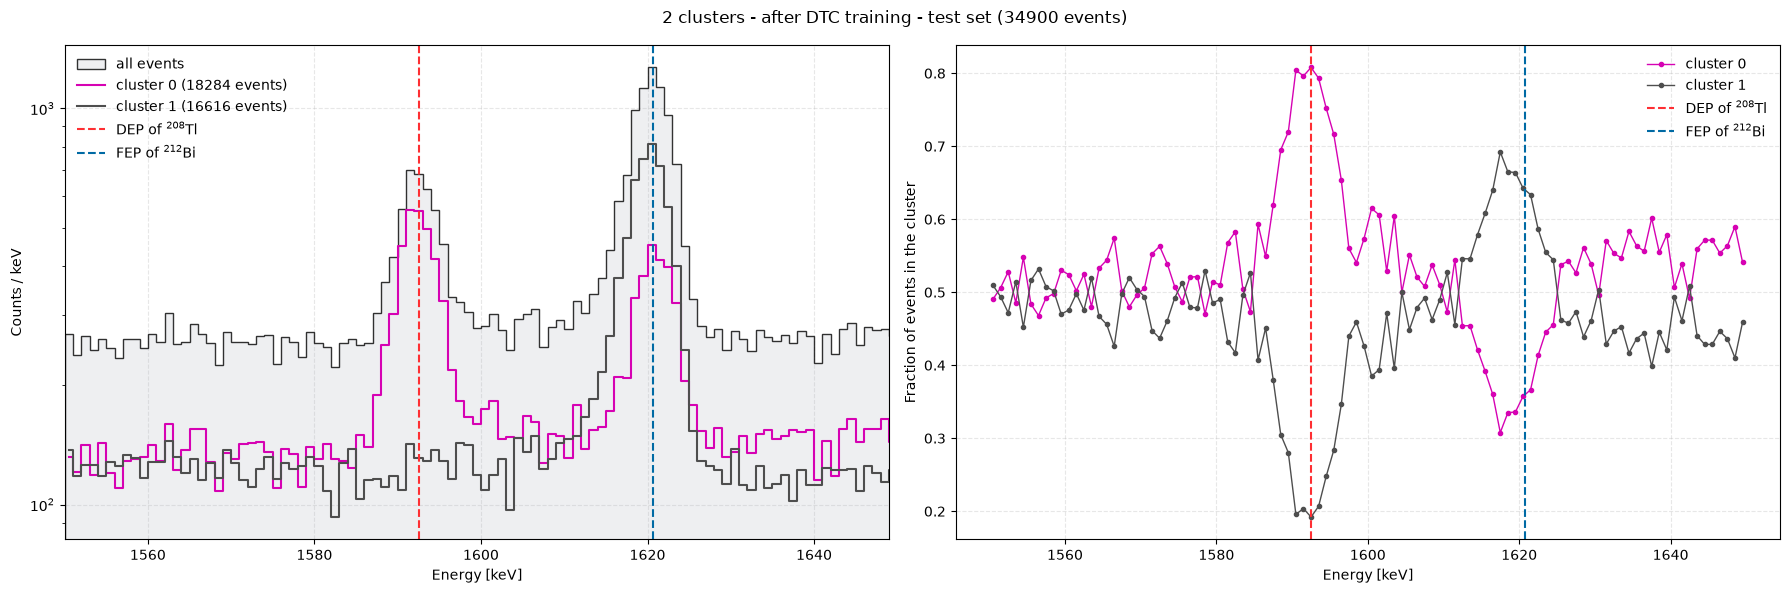

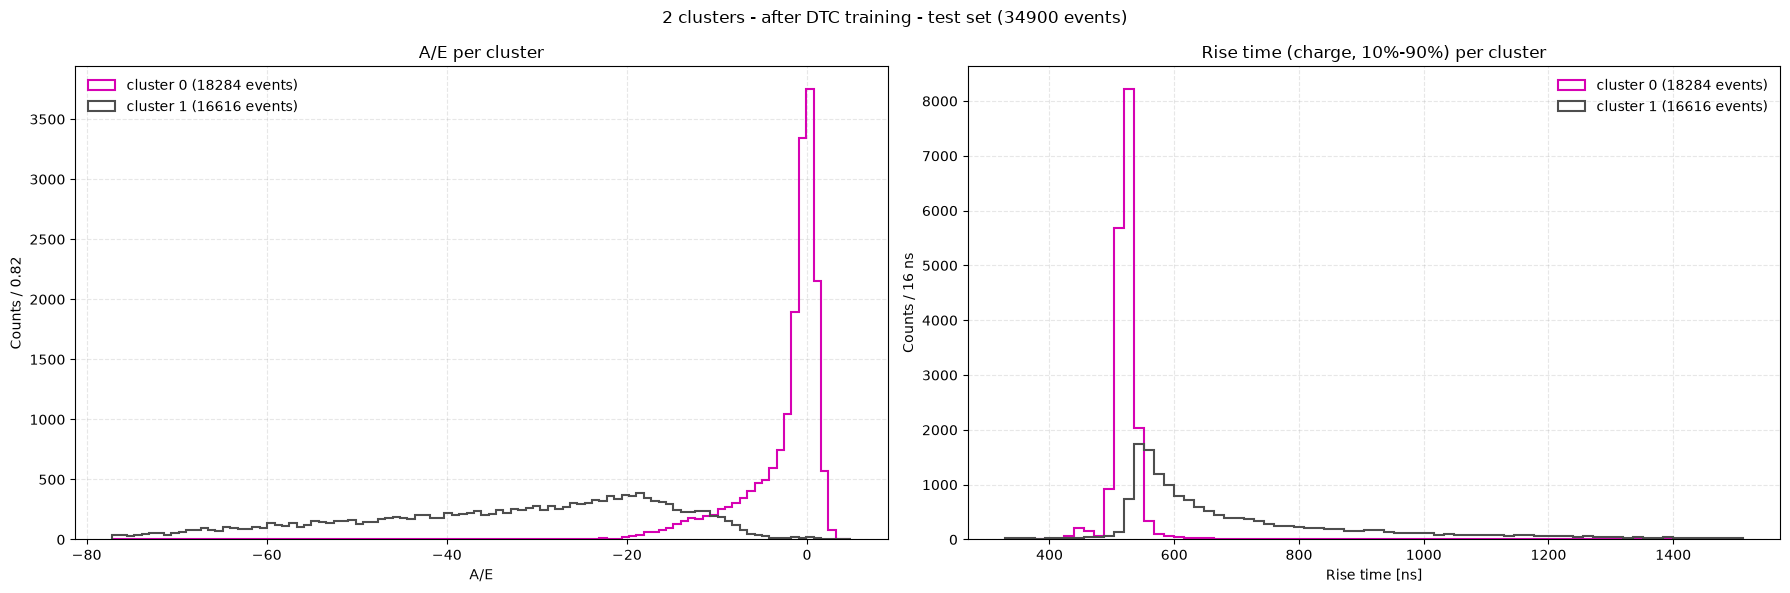

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-806.05,-804.51,-810.83,-811.37,0.00,0.01,58.36,0.34/0.66
2,-791.23,-751.49,-805.36,-787.03,0.01,0.04,23.75,0.57/0.43
3,-709.74,-697.52,-770.92,-769.17,0.06,0.07,6.52,0.51/0.49
4,-692.57,-695.31,-766.55,-770.76,0.07,0.08,1.72,0.50/0.50
5,-691.68,-694.38,-768.15,-771.61,0.08,0.08,0.53,0.49/0.51
6,-691.27,-690.66,-768.99,-768.75,0.08,0.08,2.74,0.52/0.48
7,-691.60,-679.15,-769.91,-757.77,0.08,0.08,2.47,0.49/0.51
8,-691.96,-691.65,-770.60,-770.49,0.08,0.08,1.69,0.51/0.49
9,-692.62,-696.27,-771.49,-775.18,0.08,0.08,1.86,0.50/0.50


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_acf_training_losses.csv | table_acf_training_losses.tex
acf: DEP per cluster [0.717 0.283] | FEP per cluster [0.385 0.615] -> SSE-like cluster = 0
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_acf_gamma1000_20ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_acf_gamma1000_20ep_bundle.pth


In [19]:
runs['acf'] = run_final('acf')

#### Euclidean

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans


Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.886 0.114]
[train] epoch 1/20 - train: -785.6019  val: -759.0666  events per cluster: [0.809 0.191]  changes: 0.0776
        NLL: -805.52   KL: 0.0199
[train] epoch 2/20 - train: -722.4192  val: -704.3394  events per cluster: [0.529 0.471]  changes: 0.2797
        NLL: -779.73   KL: 0.0573
[train] epoch 3/20 - train: -696.2592  val: -693.6552  events per cluster: [0.504 0.496]  changes: 0.0277
        NLL: -770.59   KL: 0.0743
[train] epoch 4/20 - train: -690.0893  val: -659.0769  events per cluster: [0.489 0.511]  changes: 0.0208
        NLL: -767.89   KL: 0.0778
[train] epoch 5/20 - train: -691.0259  val: -695.7863  events per cluster: [0.489 0.511]  changes: 0.0058
        NLL: -768.47   KL: 0.0774
[train] epoch 6/20 - train: -694.8164  val: -699.4481  events per cluster: [0.451 0.549]  changes: 0.0379
        NLL: -771.87   KL: 0.0771
[train] epoch 7/20 - train: -697.1758  val: -700.36

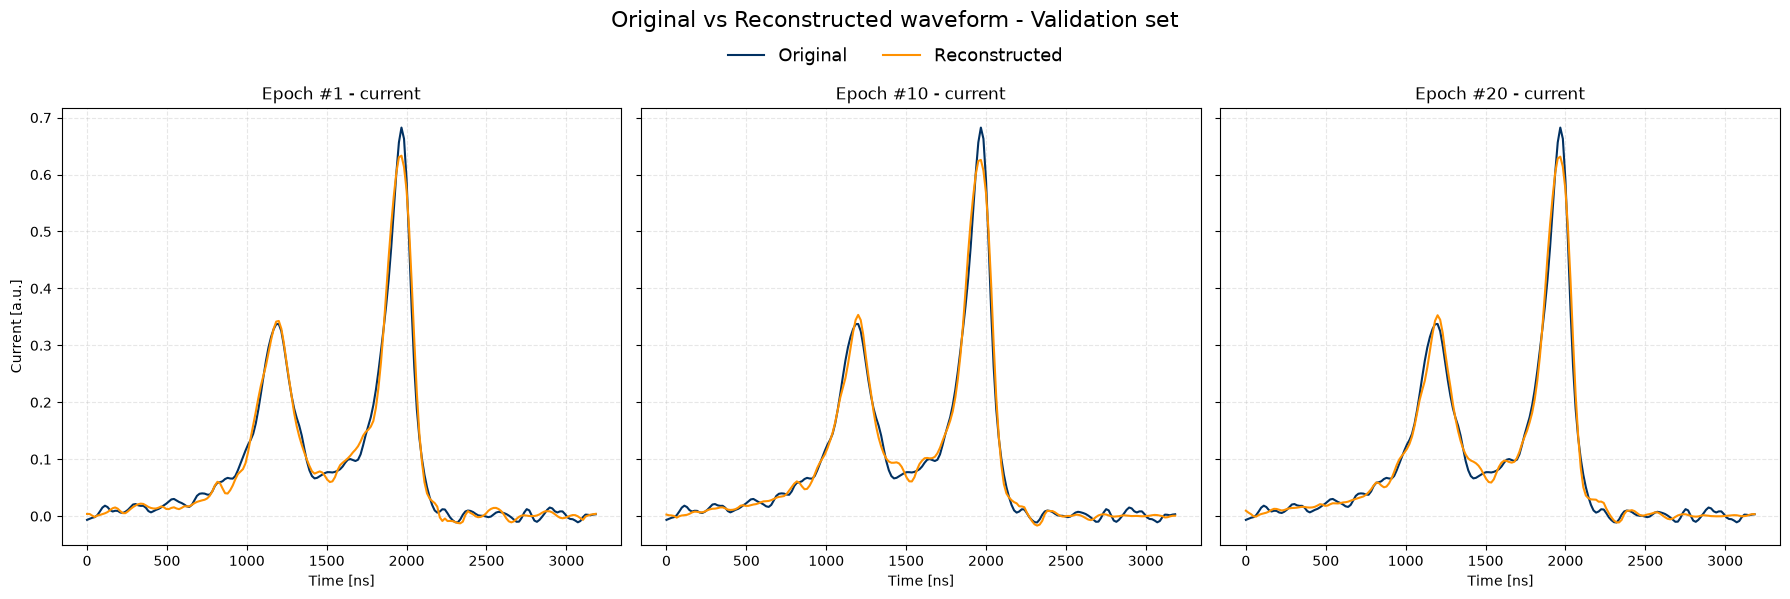

[euclidean, gamma=1000, 2 clusters] events that changed cluster with the training: 0.3960


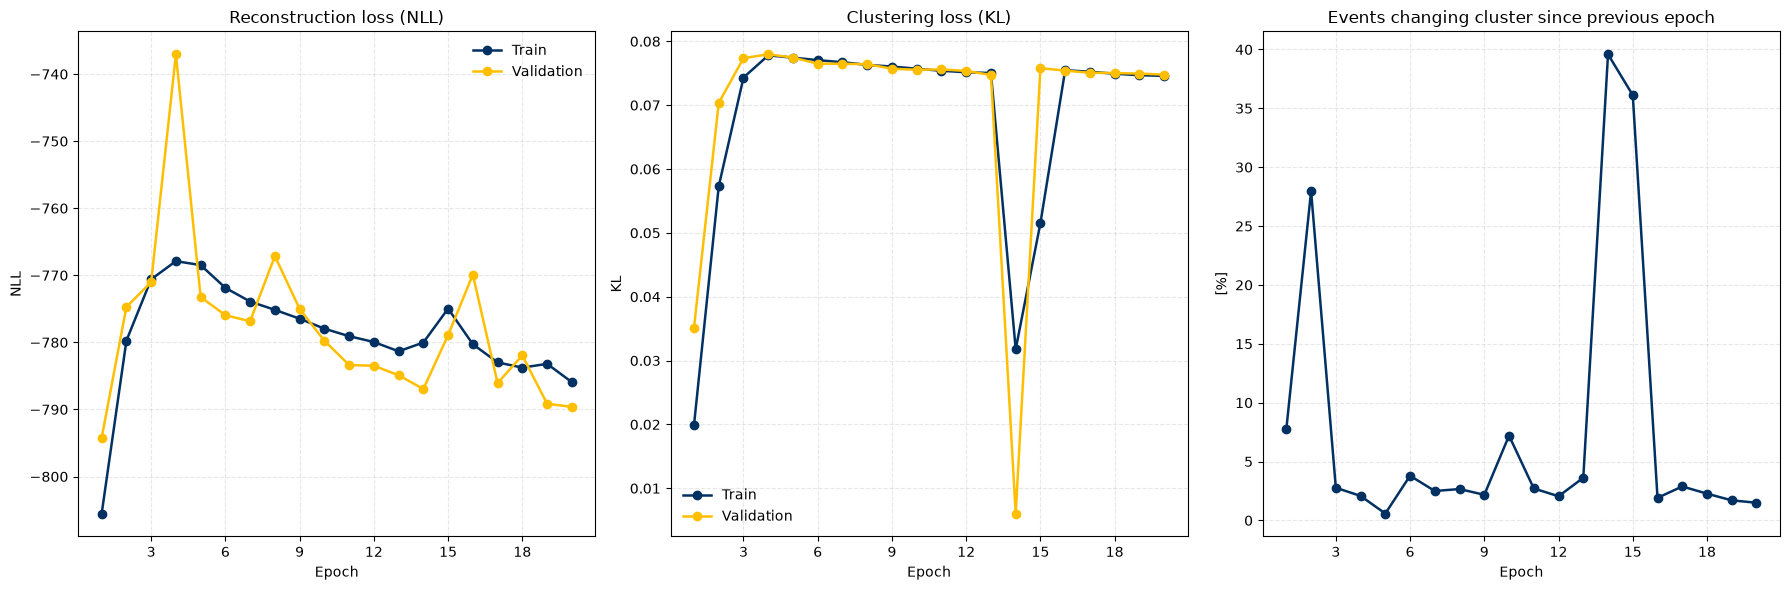

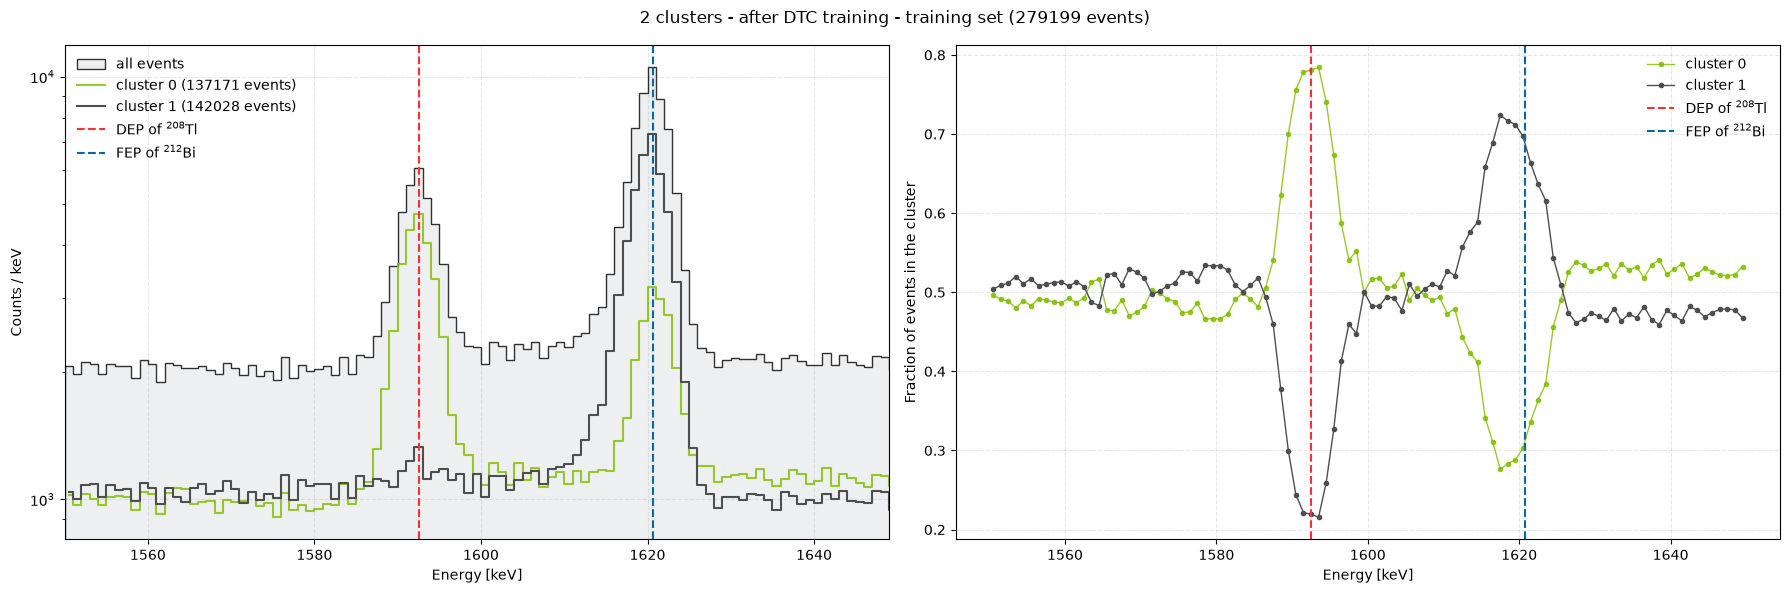

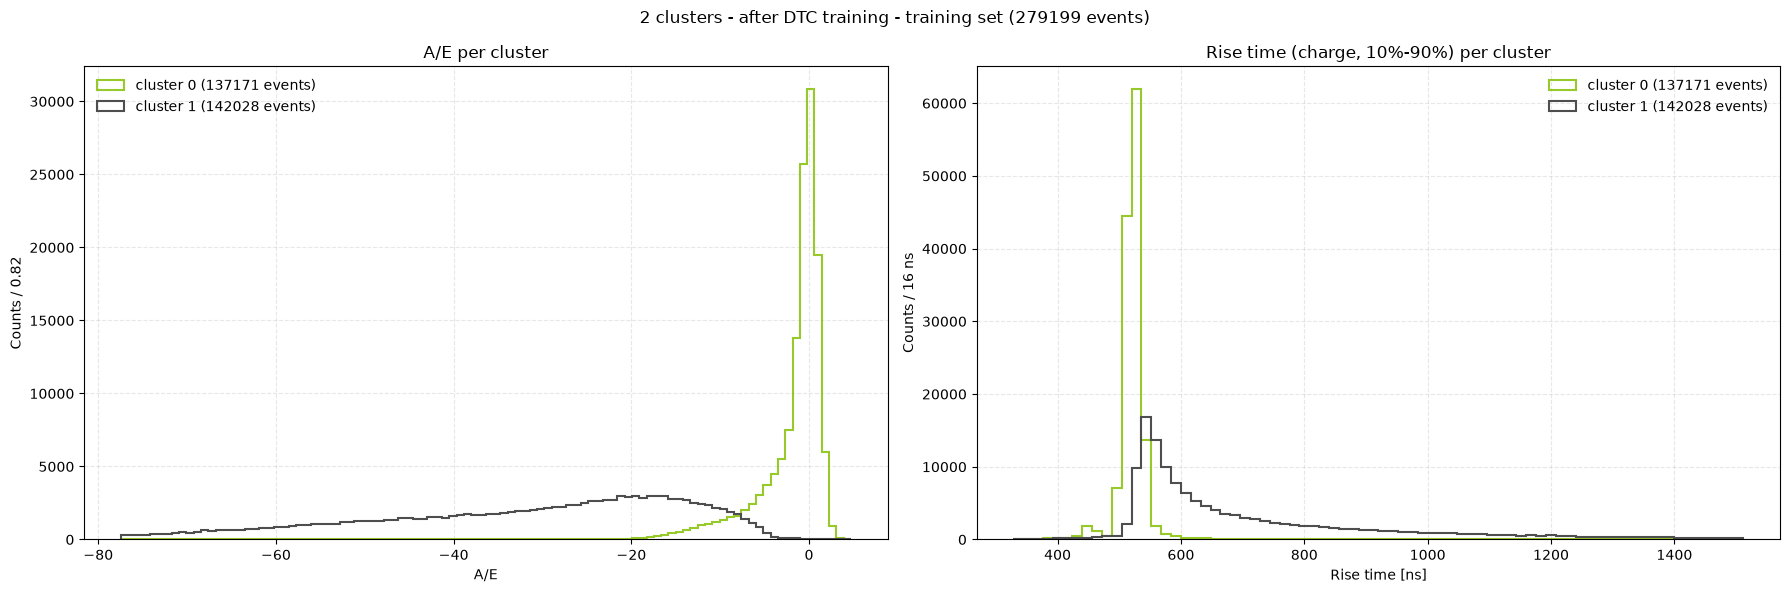

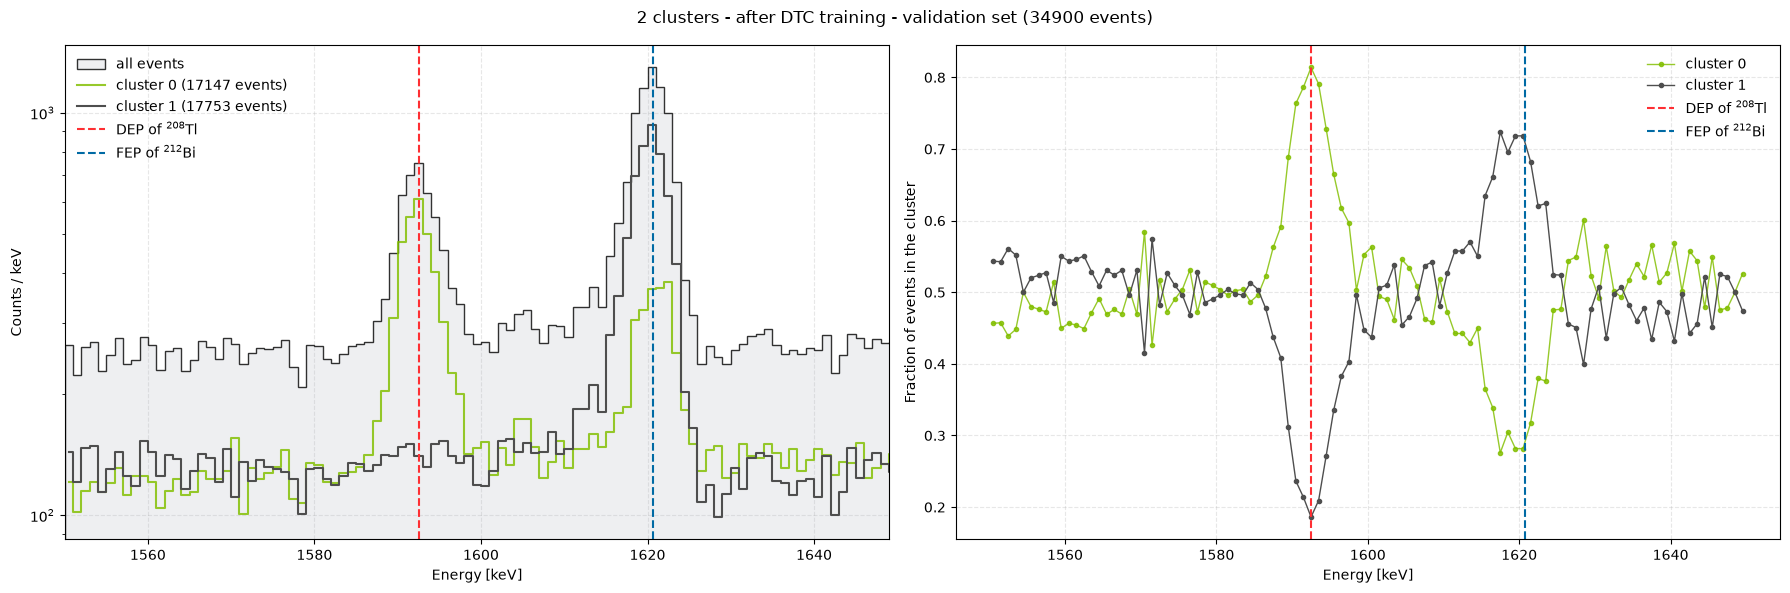

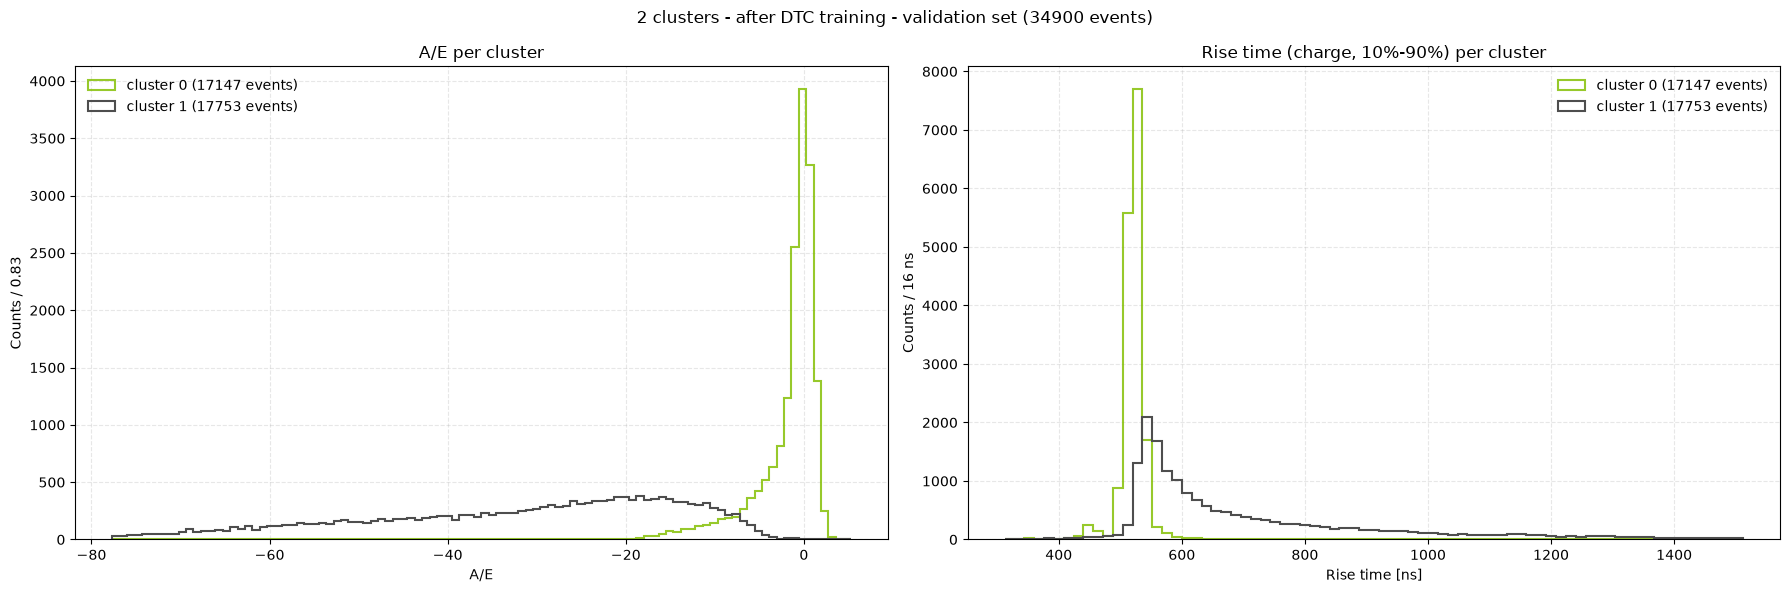

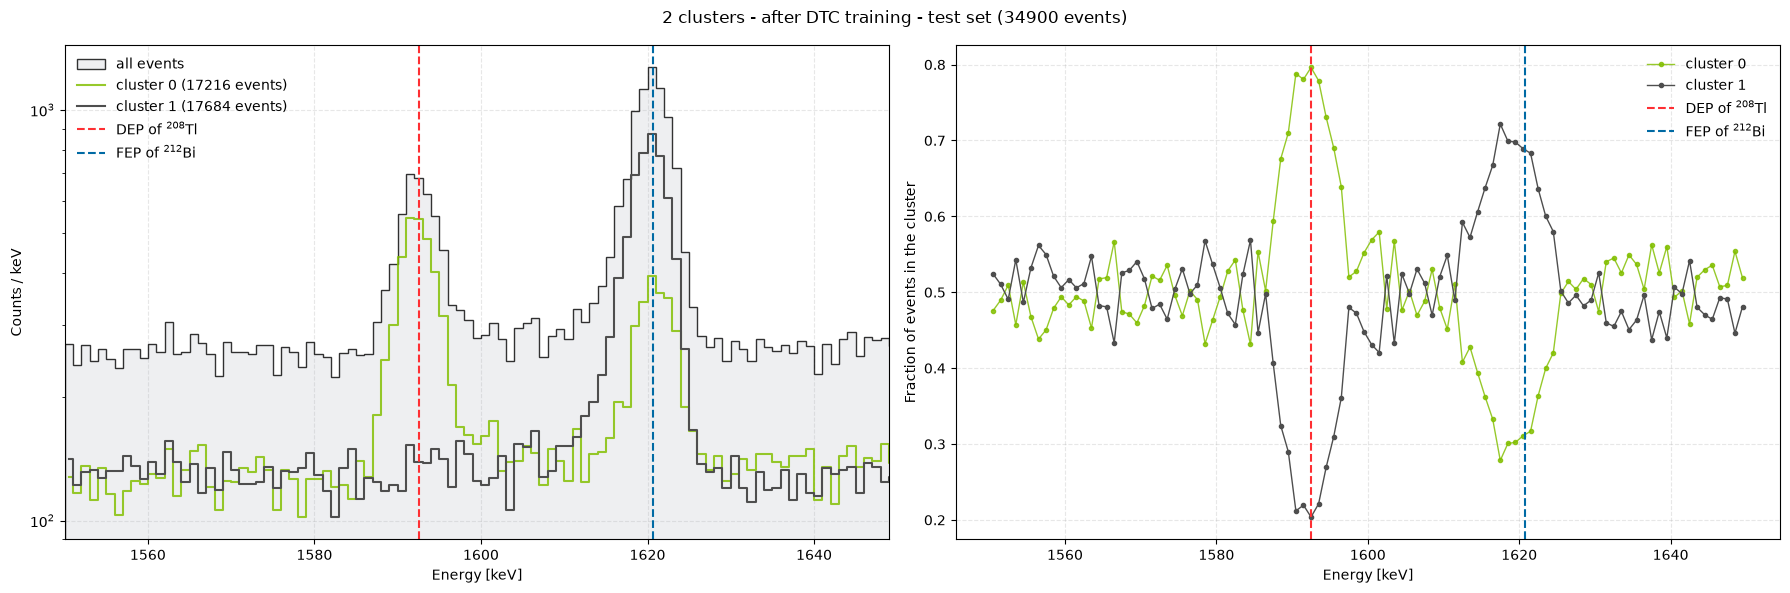

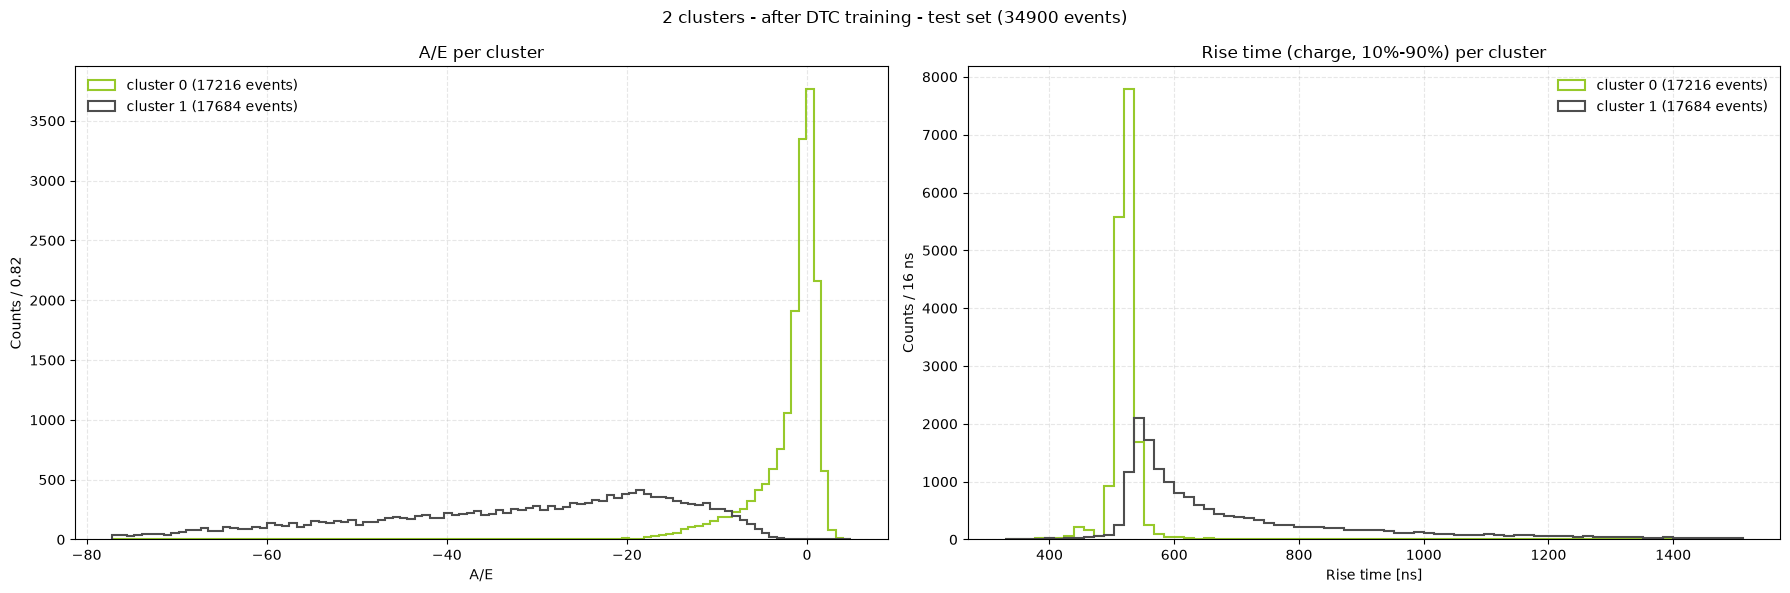

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-785.60,-759.07,-805.52,-794.23,0.02,0.04,7.76,0.81/0.19
2,-722.42,-704.34,-779.73,-774.71,0.06,0.07,27.97,0.53/0.47
3,-696.26,-693.66,-770.59,-771.02,0.07,0.08,2.77,0.50/0.50
4,-690.09,-659.08,-767.89,-737.05,0.08,0.08,2.08,0.49/0.51
5,-691.03,-695.79,-768.47,-773.24,0.08,0.08,0.58,0.49/0.51
6,-694.82,-699.45,-771.87,-775.95,0.08,0.08,3.79,0.45/0.55
7,-697.18,-700.36,-773.91,-776.85,0.08,0.08,2.50,0.48/0.52
8,-698.84,-690.71,-775.15,-767.12,0.08,0.08,2.66,0.48/0.52
9,-700.42,-699.30,-776.47,-775.01,0.08,0.08,2.17,0.46/0.54


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_eucl_training_losses.csv | table_eucl_training_losses.tex
euclidean: DEP per cluster [0.697 0.303] | FEP per cluster [0.345 0.655] -> SSE-like cluster = 0
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_euclidean_gamma1000_20ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_euclidean_gamma1000_20ep_bundle.pth


In [20]:
runs['eucl'] = run_final('eucl')

#### CID

Clusters initialisation on the device: cuda
Centroids initialisation via KMeans


Clusters initialised
Training on the device: cuda
Initial (after KMeans) - events per cluster: [0.909 0.091]
[train] epoch 1/20 - train: -731.8122  val: -732.3675  events per cluster: [0.508 0.492]  changes: 0.4009
        NLL: -770.52   KL: 0.0387
[train] epoch 2/20 - train: -748.2670  val: -755.1632  events per cluster: [0.498 0.502]  changes: 0.0103
        NLL: -772.80   KL: 0.0245
[train] epoch 3/20 - train: -757.5109  val: -762.9501  events per cluster: [0.513 0.487]  changes: 0.0168
        NLL: -776.94   KL: 0.0194
[train] epoch 4/20 - train: -762.1227  val: -768.2694  events per cluster: [0.495 0.505]  changes: 0.0183
        NLL: -778.52   KL: 0.0164
[train] epoch 5/20 - train: -768.4080  val: -775.9374  events per cluster: [0.509 0.491]  changes: 0.0150
        NLL: -782.80   KL: 0.0144
[train] epoch 6/20 - train: -770.2190  val: -778.0008  events per cluster: [0.528 0.472]  changes: 0.0191
        NLL: -783.26   KL: 0.0130
[train] epoch 7/20 - train: -773.8517  val: -777.56

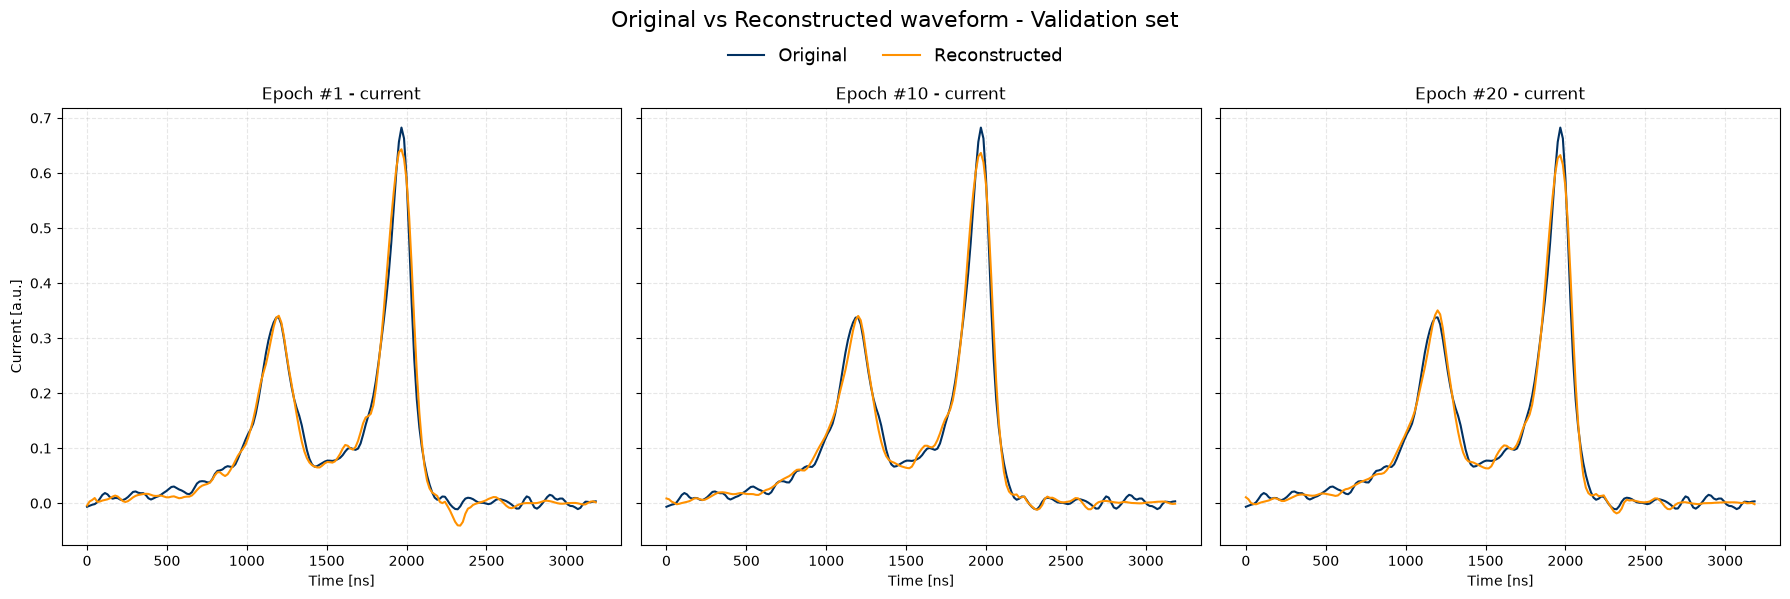

[cid, gamma=1000, 2 clusters] events that changed cluster with the training: 0.4465


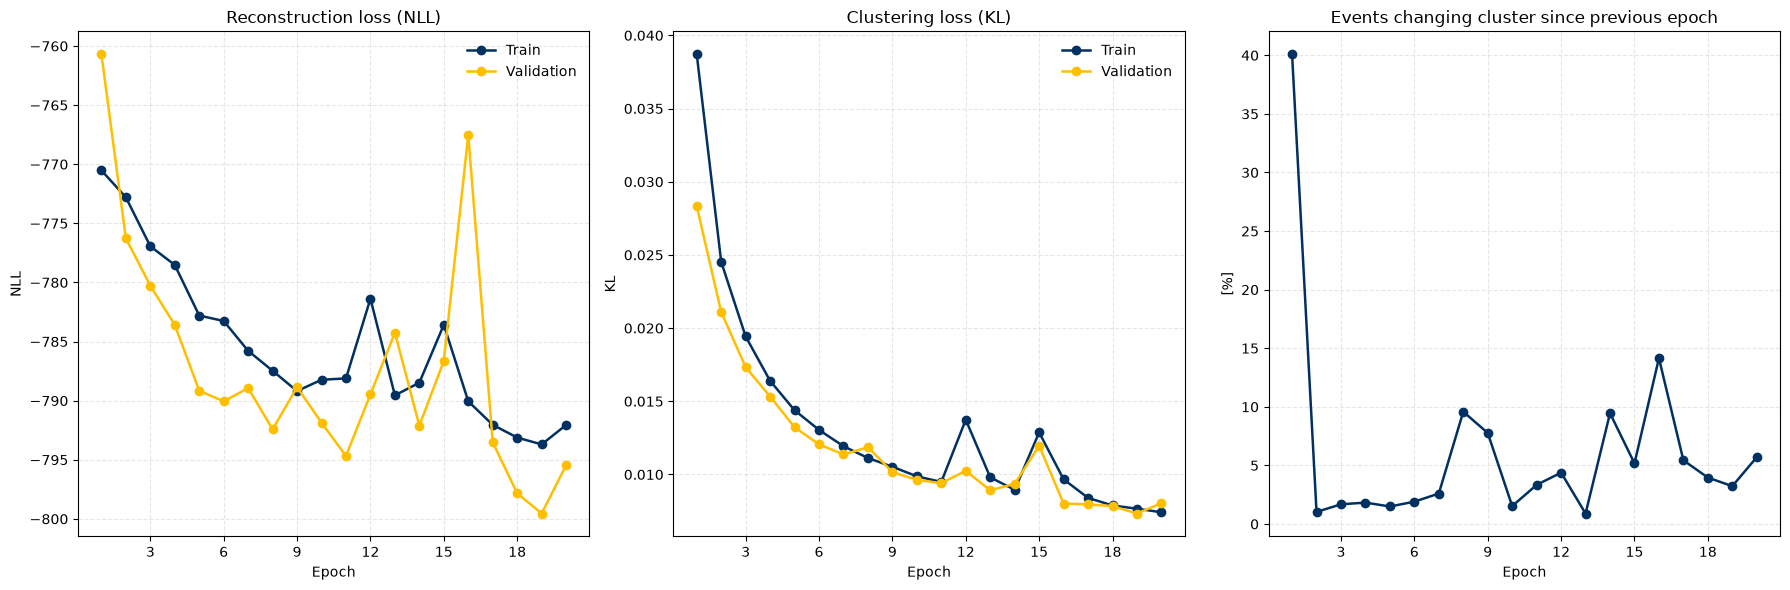

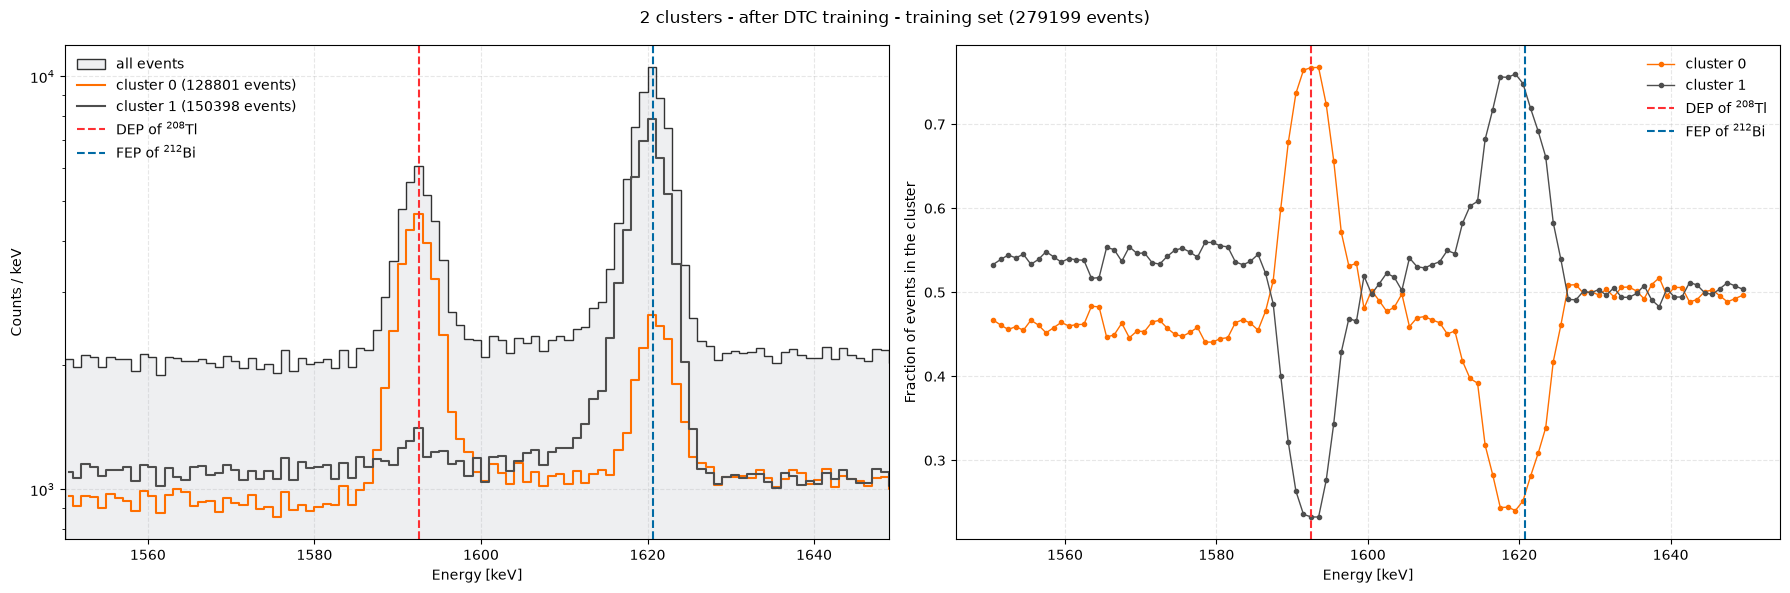

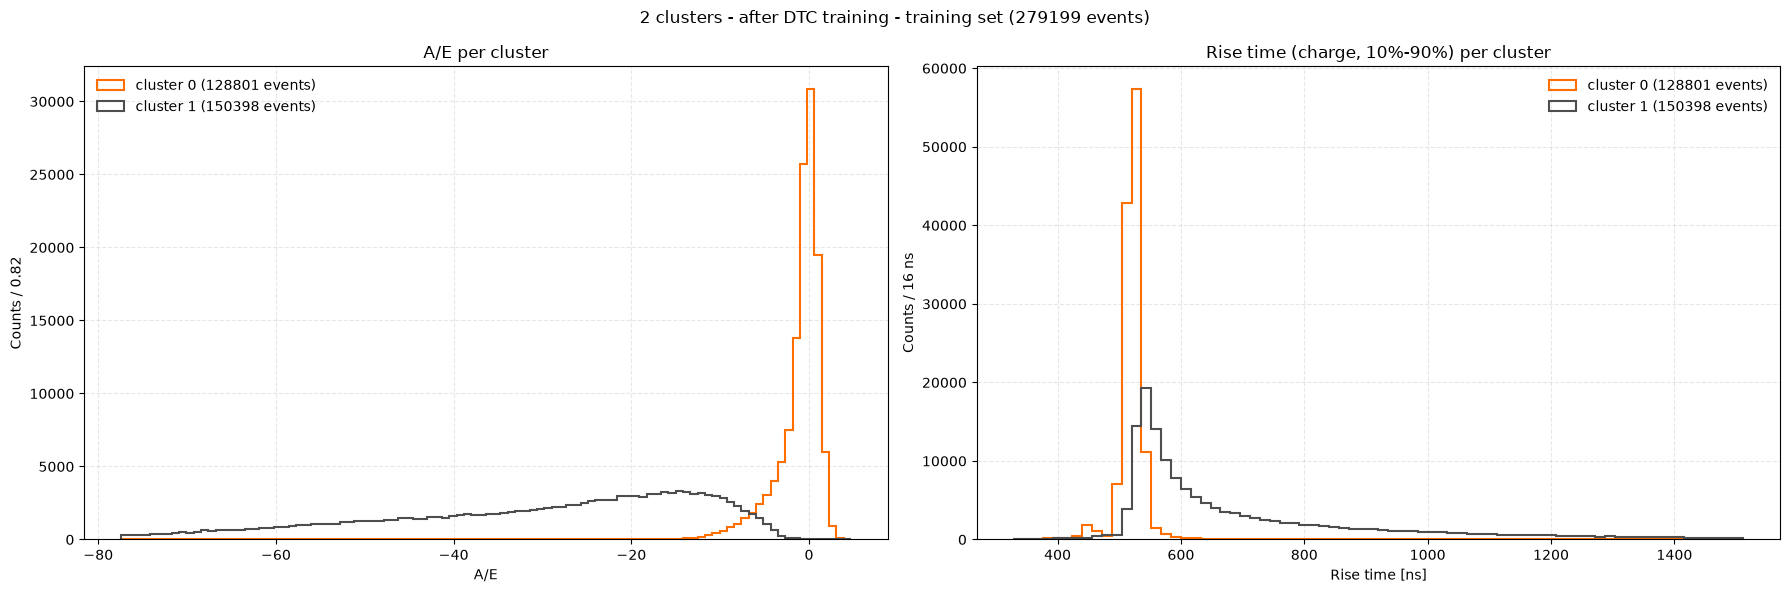

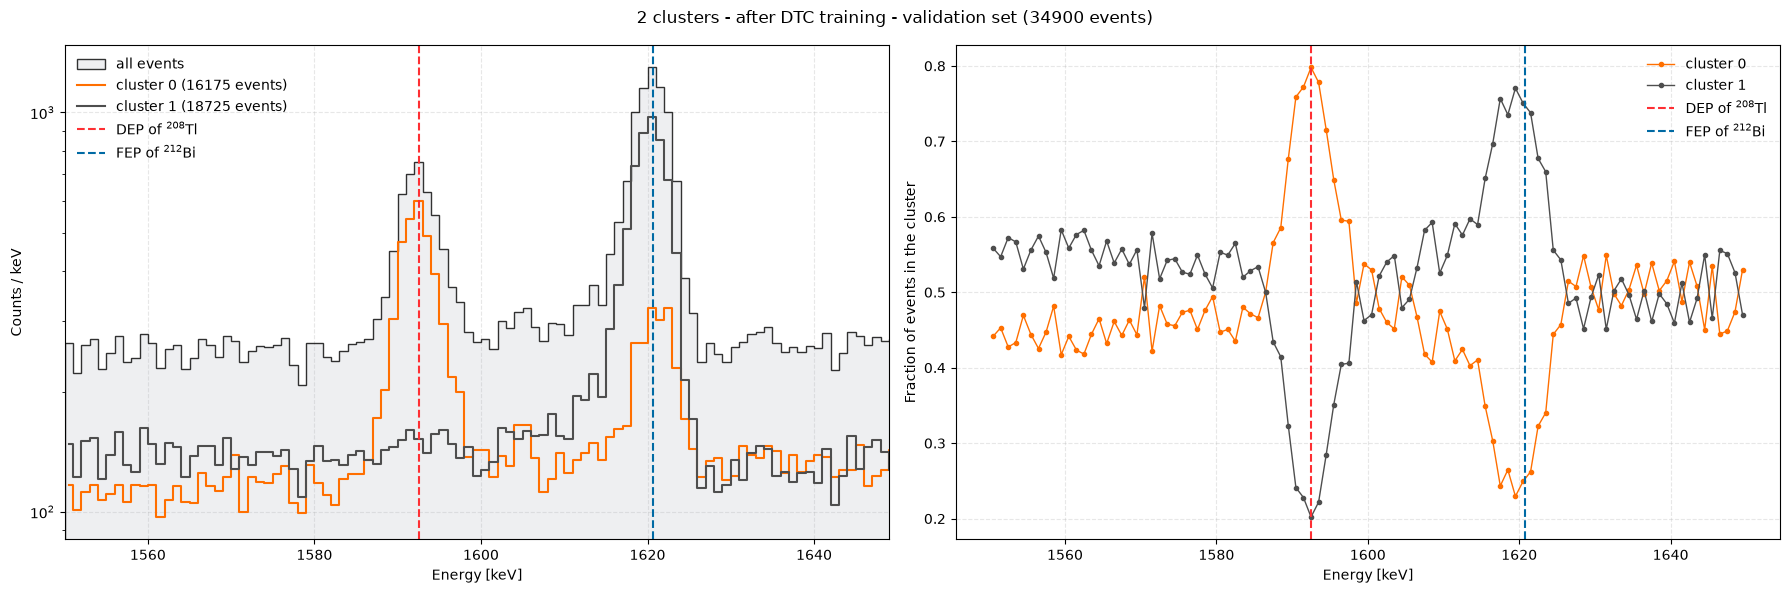

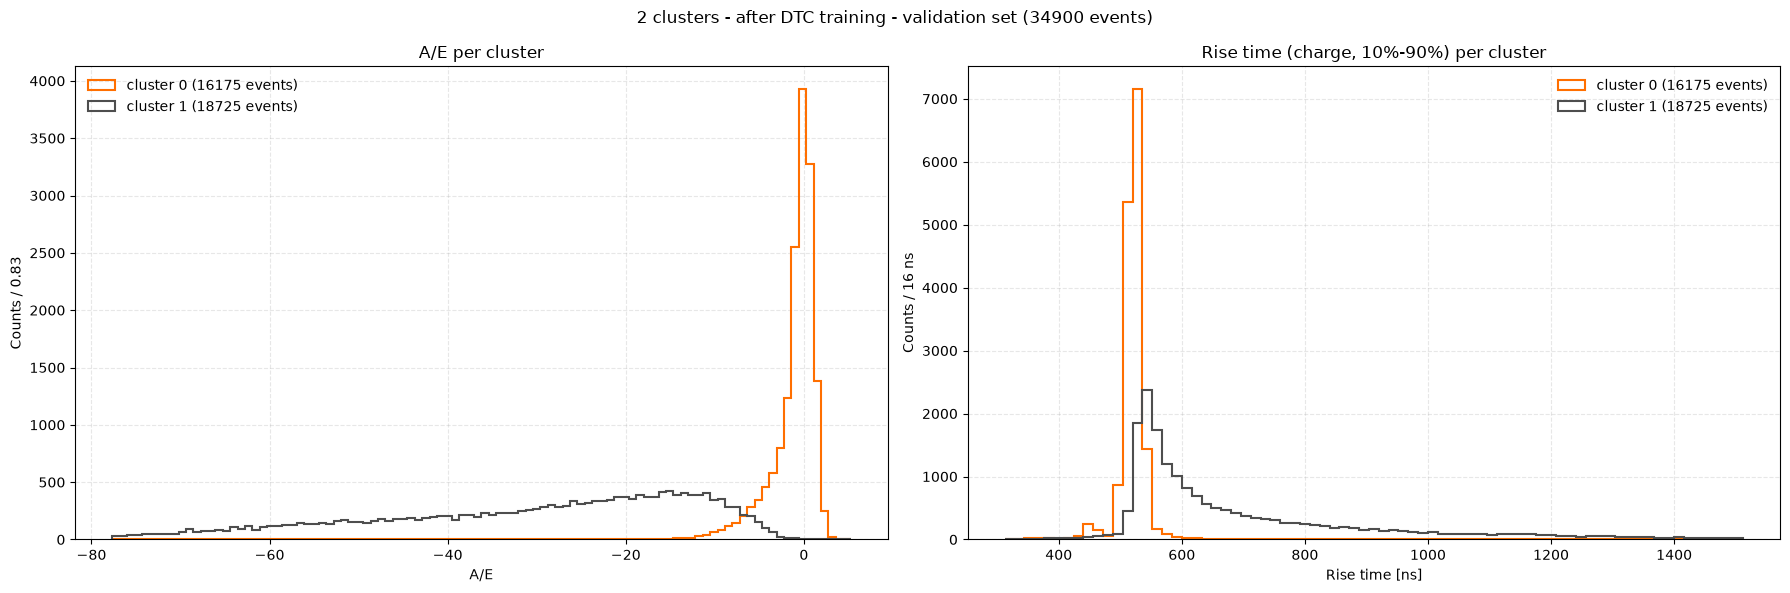

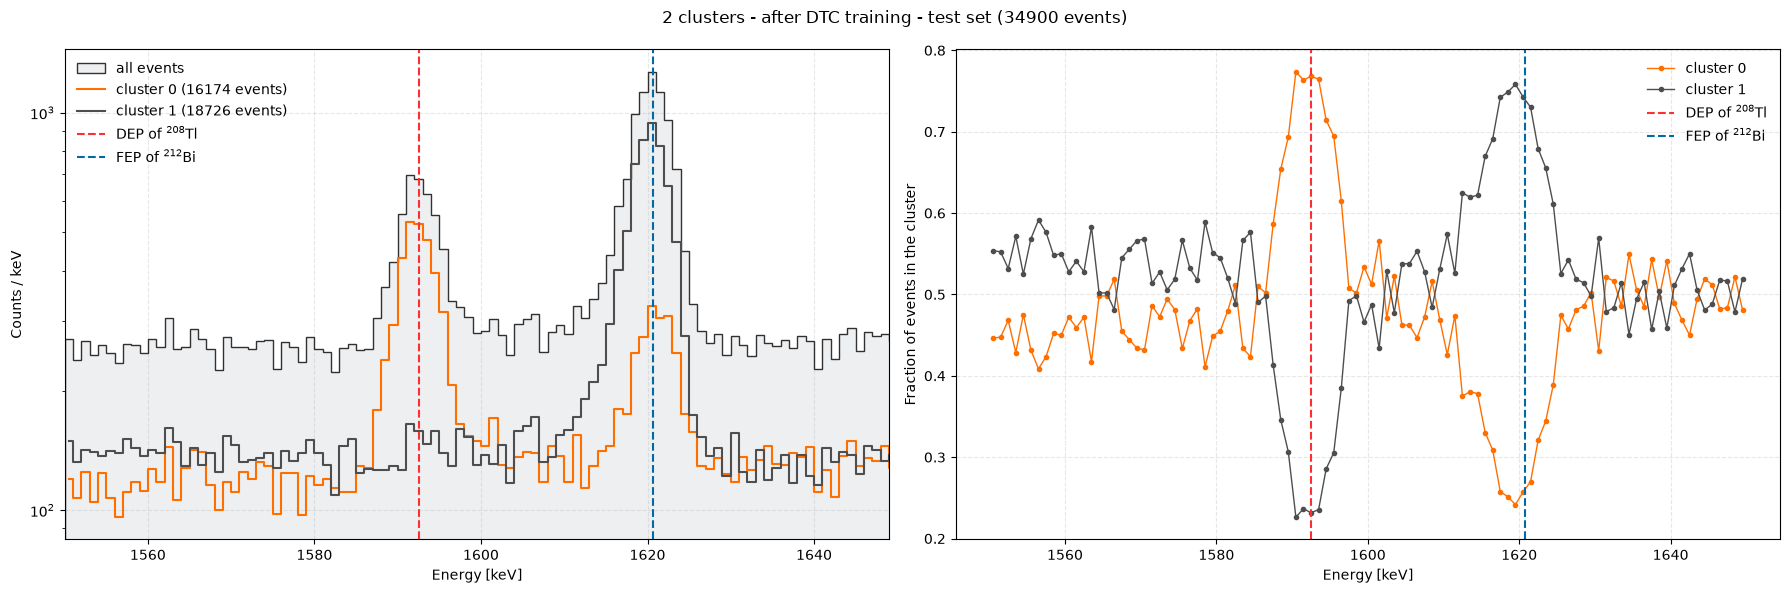

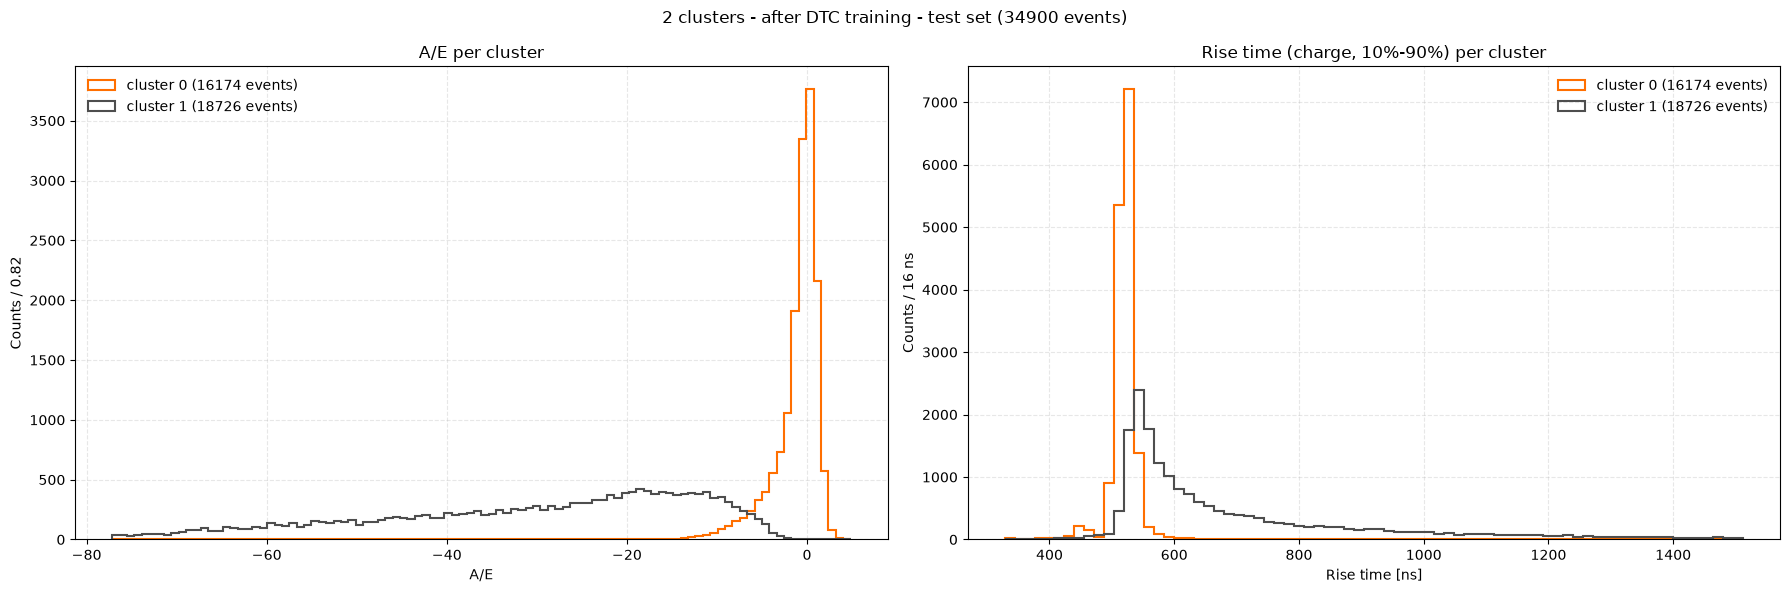

,total train,total validation,NLL train,NLL validation,KL train,KL validation,changes [%],events per cluster
epoch,,,,,,,,
1,-731.81,-732.37,-770.52,-760.70,0.04,0.03,40.09,0.51/0.49
2,-748.27,-755.16,-772.80,-776.26,0.02,0.02,1.03,0.50/0.50
3,-757.51,-762.95,-776.94,-780.27,0.02,0.02,1.68,0.51/0.49
4,-762.12,-768.27,-778.52,-783.59,0.02,0.02,1.83,0.50/0.50
5,-768.41,-775.94,-782.80,-789.16,0.01,0.01,1.50,0.51/0.49
6,-770.22,-778.00,-783.26,-790.05,0.01,0.01,1.91,0.53/0.47
7,-773.85,-777.57,-785.78,-788.93,0.01,0.01,2.60,0.53/0.47
8,-776.35,-780.56,-787.47,-792.42,0.01,0.01,9.58,0.44/0.56
9,-778.66,-778.70,-789.19,-788.86,0.01,0.01,7.77,0.51/0.49


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_cid_training_losses.csv | table_cid_training_losses.tex
cid: DEP per cluster [0.68 0.32] | FEP per cluster [0.303 0.697] -> SSE-like cluster = 0
saved: /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_cid_gamma1000_20ep.pth | /storage/rasera/DeepTemporalClusteringForL200/file_butter/finalmodels/dtc2_cid_gamma1000_20ep_bundle.pth


In [21]:
runs['cid'] = run_final('cid')

# 4. COMPARISON OF THE METRICS
Fraction of events kept by each metric (= events in its SSE-like cluster), in total and in the DEP and FEP windows, on every set.
A/E is available only on the whole calibration dataset (the events after the A/E cut are cleaned as a separate set).
Raw counts in the windows, no background subtraction: the same for every row, so the rows are comparable.

In [22]:
split_names = {'train': 'training', 'val': 'validation', 'test': 'test', 'all': 'whole dataset'}
rows = []
for tag, r in runs.items():
    keep = r['y'] == r['sse_cluster']
    for split in ('train', 'val', 'test', 'all'):
        idx = np.arange(len(energy)) if split == 'all' else data[f'idx_{split}']
        k, d, f = keep[idx], in_dep[idx], in_fep[idx]
        rows.append({'cut / set': f"{NAMES[tag]} / {split_names[split]}",
                     'kept [%]': 100 * k.mean(), 'DEP kept [%]': 100 * k[d].mean(), 'FEP kept [%]': 100 * k[f].mean()})

e_all, e_aoe = clean['energy_all'], clean['energy_AoE_all']
win = lambda e, p: np.abs(e - p[1]) <= 3 * p[2]
rows.append({'cut / set': 'A/E / whole dataset',
             'kept [%]': 100 * len(e_aoe) / len(e_all),
             'DEP kept [%]': 100 * win(e_aoe, dep).sum() / win(e_all, dep).sum(),
             'FEP kept [%]': 100 * win(e_aoe, fep).sum() / win(e_all, fep).sum()})
save_table(pd.DataFrame(rows).set_index('cut / set'), 'table_metrics_comparison')

,kept [%],DEP kept [%],FEP kept [%]
cut / set,,,
ACF / training,52.43,71.55,38.47
ACF / validation,52.32,72.15,38.21
ACF / test,52.39,72.44,38.60
ACF / whole dataset,52.41,71.70,38.45
Euclidean / training,49.13,69.50,34.42
Euclidean / validation,49.13,70.11,34.48
Euclidean / test,49.33,70.52,34.72
Euclidean / whole dataset,49.15,69.66,34.45
CID / training,46.13,67.75,30.23


saved: /storage/rasera/DeepTemporalClusteringForL200/finalplots/table_metrics_comparison.csv | table_metrics_comparison.tex
